In [8]:
# Mount Google Drive
from google.colab import drive
drive.mount('/content/drive')

# Note: After running this cell, you can find your zip file in drive (e.g., '/content/drive/MyDrive/dataset.zip')
# and update the `zip_path` variable in the extraction cell below.

Mounted at /content/drive


In [9]:
# ==========================================
# CELL 1: SETUP & FILE UPLOAD / EXTRACTION
# ==========================================
import os
import zipfile
import glob
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image

import tensorflow as tf
from tensorflow.keras import layers, models
from sklearn.metrics import classification_report, confusion_matrix

# 1. Unzip the dataset
zip_path = '/content/drive/MyDrive/PBC_dataset_normal_DIB.zip'
extract_dir = './extracted_cells'

if os.path.exists(zip_path):
    with zipfile.ZipFile(zip_path, 'r') as zip_ref:
        zip_ref.extractall(extract_dir)
    print("Dataset extracted successfully!")
else:
    print(f"Please upload your zip file as '{zip_path}' or update the `zip_path` variable.")

# 2. Automatically locate the true data directory (ignoring metadata folders like __MACOSX)
def find_class_data_dir(root_dir):
    for root, dirs, files in os.walk(root_dir):
        # Exclude macOS metadata directories entirely from exploration
        if '__MACOSX' in root:
            continue
        dirs[:] = [d for d in dirs if d != '__MACOSX']

        # Check if the directories inside 'root' contain actual images
        for d in dirs:
            class_path = os.path.join(root, d)
            try:
                any_images = any(f.lower().endswith(('.png', '.jpg', '.jpeg', '.bmp')) for f in os.listdir(class_path) if os.path.isfile(os.path.join(class_path, f)))
                if any_images:
                    return root
            except Exception:
                continue
    return root_dir

data_dir = find_class_data_dir(extract_dir)
print(f"Data directory: {data_dir}")

Dataset extracted successfully!
Data directory: ./extracted_cells/PBC_dataset_normal_DIB


Total Images Found: 17092

Class Distribution:
basophil        1218
eosinophil      3117
erythroblast    1551
ig              2895
lymphocyte      1214
monocyte        1420
neutrophil      3329
platelet        2348
dtype: int64


/tmp/ipykernel_497/2718200566.py:32: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=list(class_counts.keys()), y=list(class_counts.values()), palette='viridis')


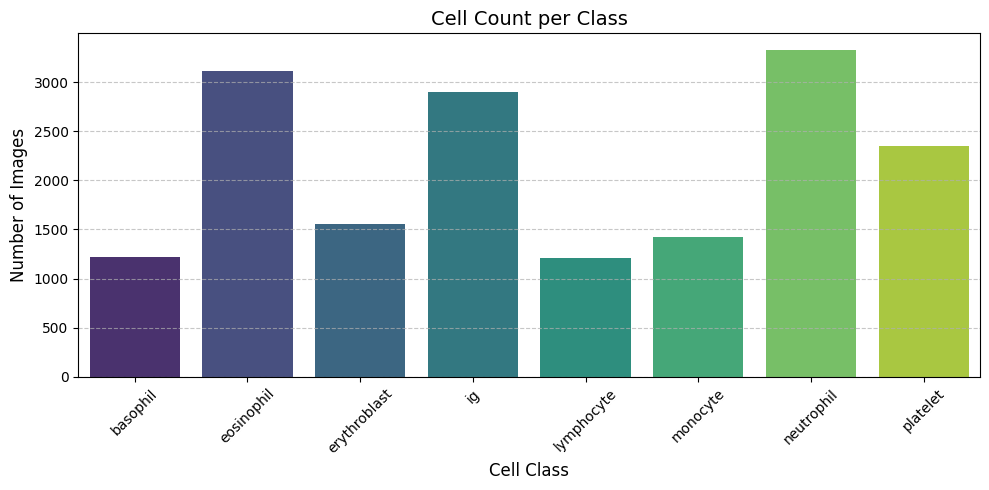

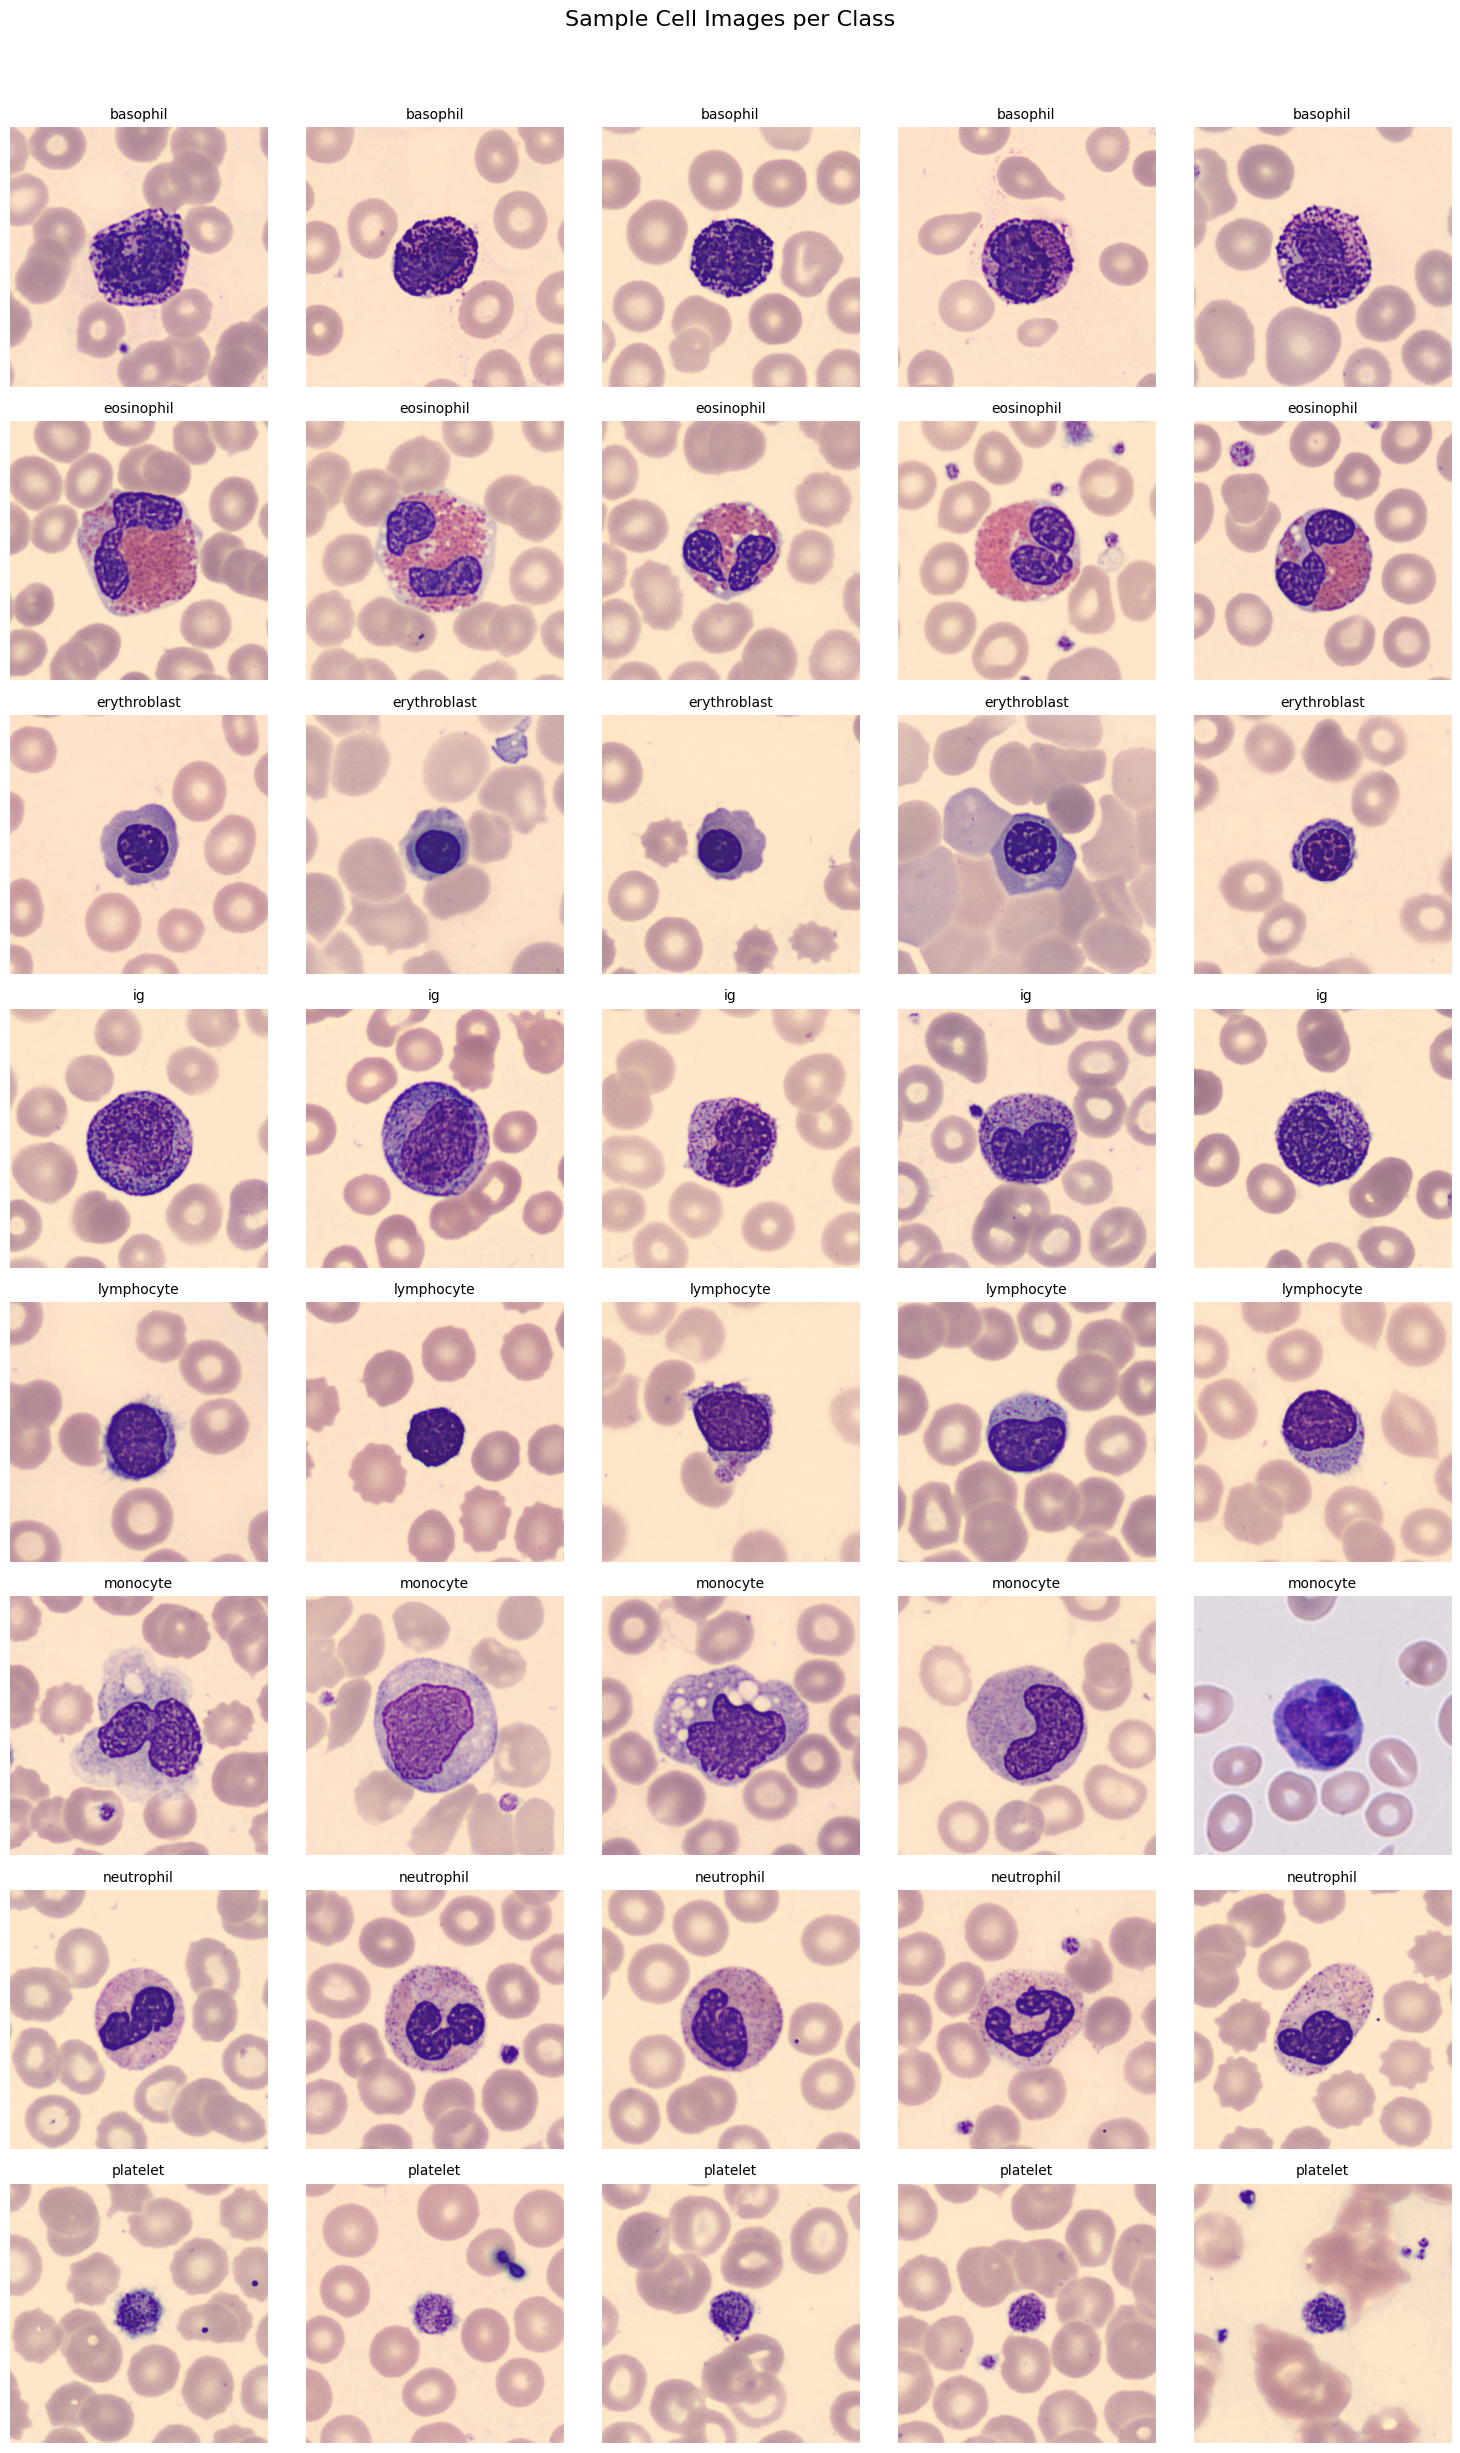

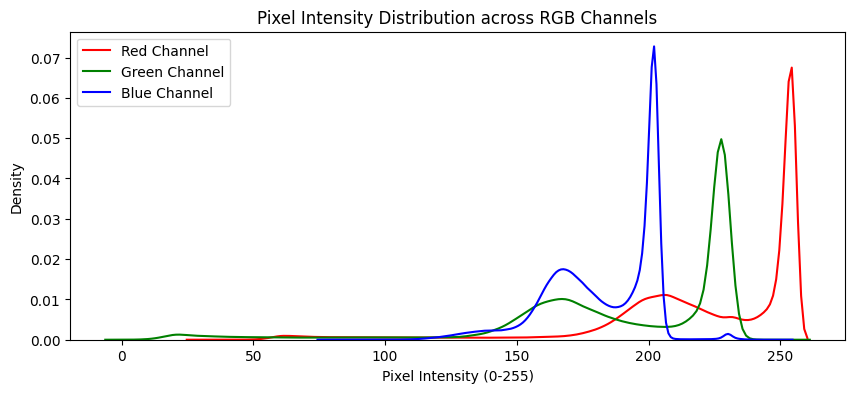

In [10]:
# ==========================================
# CELL 2: DATASET MAPPING & VISUALIZATION
# ==========================================

# 1. Map class distributions
valid_exts = ('*.jpg', '*.jpeg', '*.png', '*.bmp', '*.tif', '*.tiff')
class_counts = {}
image_paths = []
labels = []

for class_name in sorted(os.listdir(data_dir)):
    class_path = os.path.join(data_dir, class_name)
    if os.path.isdir(class_path):
        files = []
        for ext in valid_exts:
            files.extend(glob.glob(os.path.join(class_path, ext)))
            files.extend(glob.glob(os.path.join(class_path, ext.upper())))

        if files:
            class_counts[class_name] = len(files)
            image_paths.extend(files)
            labels.extend([class_name] * len(files))

df = pd.DataFrame({'image_path': image_paths, 'label': labels})

print(f"Total Images Found: {len(df)}")
print("\nClass Distribution:")
print(pd.Series(class_counts))

# 2. Plot Class Distribution
plt.figure(figsize=(10, 5))
sns.barplot(x=list(class_counts.keys()), y=list(class_counts.values()), palette='viridis')
plt.title('Cell Count per Class', fontsize=14)
plt.xlabel('Cell Class', fontsize=12)
plt.ylabel('Number of Images', fontsize=12)
plt.xticks(rotation=45)
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

# 3. Visualize Sample Images across Classes
unique_classes = list(class_counts.keys())
fig, axes = plt.subplots(len(unique_classes), 5, figsize=(15, 3 * len(unique_classes)))

for idx, cls in enumerate(unique_classes):
    cls_files = df[df['label'] == cls]['image_path'].sample(min(5, class_counts[cls]), random_state=42).values
    for j, img_p in enumerate(cls_files):
        ax = axes[idx, j] if len(unique_classes) > 1 else axes[j]
        img = Image.open(img_p)
        ax.imshow(img)
        ax.set_title(f"{cls}", fontsize=10)
        ax.axis('off')

plt.suptitle('Sample Cell Images per Class', fontsize=16, y=1.02)
plt.tight_layout()
plt.show()

# 4. Color Channel Analysis (RGB Distribution)
sample_imgs = df.sample(min(50, len(df)), random_state=42)['image_path'].values
r_vals, g_vals, b_vals = [], [], []

for p in sample_imgs:
    img = np.array(Image.open(p).convert('RGB'))
    r_vals.extend(img[:, :, 0].flatten())
    g_vals.extend(img[:, :, 1].flatten())
    b_vals.extend(img[:, :, 2].flatten())

plt.figure(figsize=(10, 4))
sns.kdeplot(r_vals, color='red', label='Red Channel')
sns.kdeplot(g_vals, color='green', label='Green Channel')
sns.kdeplot(b_vals, color='blue', label='Blue Channel')
plt.title('Pixel Intensity Distribution across RGB Channels')
plt.xlabel('Pixel Intensity (0-255)')
plt.legend()
plt.show()

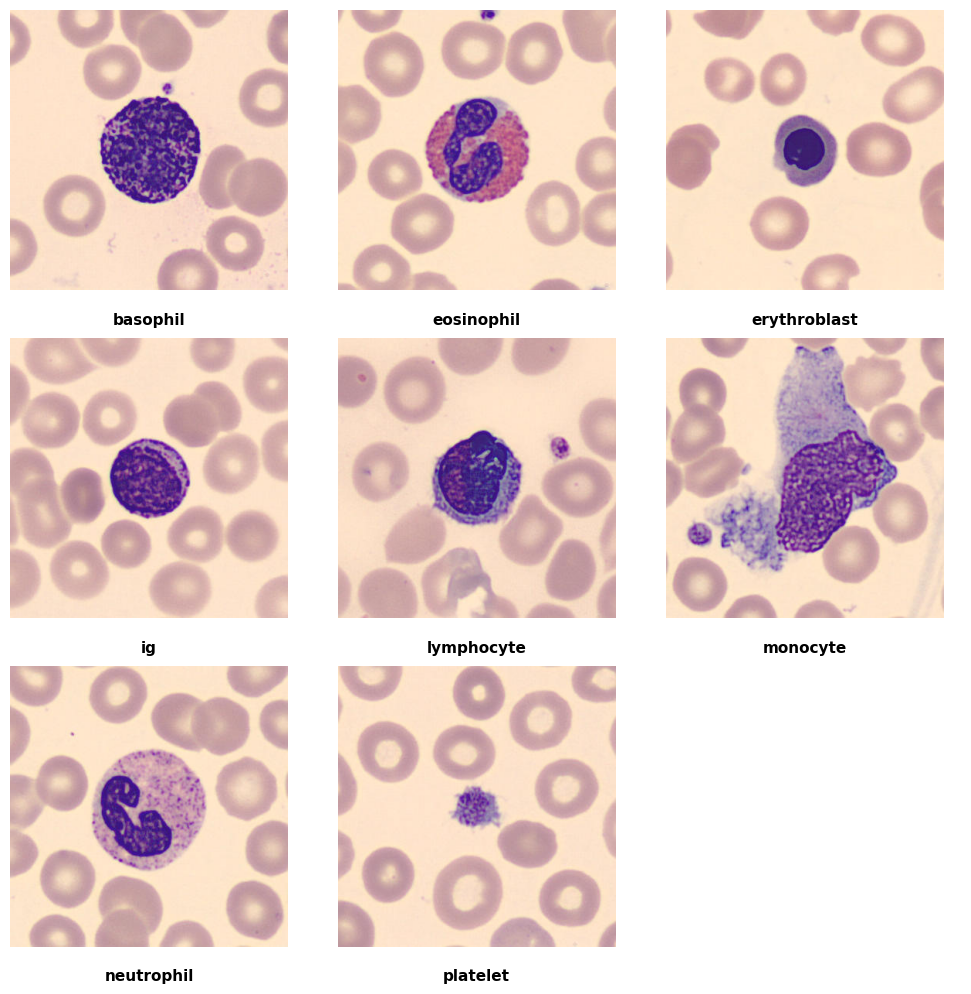

In [11]:
# ==========================================
# VISUALIZE ONE SAMPLE FROM EACH CLASS (3x3 GRID)
# ==========================================
import os
import glob
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

# Fallback for data_dir
try:
    _current_data_dir = data_dir
except NameError:
    _current_data_dir = './extracted_cells/PBC_dataset_normal_DIB'

# Safely ensure df is defined even if previous cells weren't run recently
try:
    df
except NameError:
    valid_exts = ('*.jpg', '*.jpeg', '*.png', '*.bmp')
    image_paths = []
    labels = []
    if os.path.exists(_current_data_dir):
        for class_name in sorted(os.listdir(_current_data_dir)):
            class_path = os.path.join(_current_data_dir, class_name)
            if os.path.isdir(class_path):
                files = []
                for ext in valid_exts:
                    files.extend(glob.glob(os.path.join(class_path, ext)))
                    files.extend(glob.glob(os.path.join(class_path, ext.upper())))
                if files:
                    image_paths.extend(files)
                    labels.extend([class_name] * len(files))
    df = pd.DataFrame({'image_path': image_paths, 'label': labels})

# Get one sample image from each class
unique_classes = sorted(df['label'].unique())

fig, axes = plt.subplots(3, 3, figsize=(10, 10))
axes = axes.flatten()

for idx, cls in enumerate(unique_classes):
    ax = axes[idx]
    # Get a single sample path for this class
    sample_path = df[df['label'] == cls]['image_path'].iloc[0]
    img = Image.open(sample_path)

    ax.imshow(img)
    ax.axis('off')
    ax.text(0.5, -0.08, cls,
                transform=ax.transAxes,
                ha='center', va='top', fontsize=11, fontweight='bold')

# Hide any unused subplots
for idx in range(len(unique_classes), 9):
    axes[idx].axis('off')

plt.tight_layout()
plt.show()

In [12]:
import os
from PIL import Image

print("Verifying and cleaning image files...")
corrupt_files_count = 0
valid_extensions = ('.jpg', '.jpeg', '.png', '.bmp')

for root, dirs, files in os.walk(data_dir):
    for file in files:
        if file.startswith('.') or not file.lower().endswith(valid_extensions):
            # Remove hidden/system or invalid files
            file_path = os.path.join(root, file)
            try:
                os.remove(file_path)
                print(f"Removed non-image/hidden file: {file_path}")
            except Exception as e:
                print(f"Failed to remove {file_path}: {e}")
            continue

        file_path = os.path.join(root, file)
        try:
            # Try opening and verifying the image structure
            with Image.open(file_path) as img:
                img.verify()  # Verify image integrity

            # Double-check readability by loading pixel data
            with Image.open(file_path) as img:
                img.load()
        except Exception as e:
            print(f"Corrupt file found and removed: {file_path} (Error: {e})")
            try:
                os.remove(file_path)
                corrupt_files_count += 1
            except Exception as delete_error:
                print(f"Failed to delete corrupt file {file_path}: {delete_error}")

print(f"Cleanup complete. Total corrupt files removed: {corrupt_files_count}")

Verifying and cleaning image files...
Removed non-image/hidden file: ./extracted_cells/PBC_dataset_normal_DIB/neutrophil/.DS_169665.jpg
Cleanup complete. Total corrupt files removed: 0


In [13]:
# ==========================================
# CELL 3: DATA PREPARATION & PIPELINE (SUBSAMPLED)
# ==========================================
import os
import glob
import pandas as pd
import tensorflow as tf

IMG_SIZE = (128, 128)
BATCH_SIZE = 32  # Reduced batch size for smaller datasets
SEED = 42

# Fallback for data_dir
try:
    _current_data_dir = data_dir
except NameError:
    _current_data_dir = './extracted_cells/PBC_dataset_normal_DIB'

# 1. Reconstruct image path DataFrame to create clean sub-samples
valid_exts = ('*.jpg', '*.jpeg', '*.png', '*.bmp')
image_paths = []
labels = []

if os.path.exists(_current_data_dir):
    for class_name in sorted(os.listdir(_current_data_dir)):
        class_path = os.path.join(_current_data_dir, class_name)
        if os.path.isdir(class_path):
            files = []
            for ext in valid_exts:
                files.extend(glob.glob(os.path.join(class_path, ext)))
                files.extend(glob.glob(os.path.join(class_path, ext.upper())))
            if files:
                image_paths.extend(files)
                labels.extend([class_name] * len(files))

df = pd.DataFrame({'image_path': image_paths, 'label': labels})

# 2. Sample exactly 500 training and 100 validation images from each class
train_dfs = []
val_dfs = []

for cls in df['label'].unique():
    cls_df = df[df['label'] == cls].sample(frac=1, random_state=SEED)  # Shuffle
    train_dfs.append(cls_df.iloc[:500])  # Take up to 500 for training
    val_dfs.append(cls_df.iloc[500:600])  # Take next 100 for validation

train_df_sub = pd.concat(train_dfs).sample(frac=1, random_state=SEED).reset_index(drop=True)
val_df_sub = pd.concat(val_dfs).sample(frac=1, random_state=SEED).reset_index(drop=True)

# Get class names list and index mapping
class_names = sorted(df['label'].unique())
num_classes = len(class_names)
class_to_idx = {name: idx for idx, name in enumerate(class_names)}

print(f"Training samples: {len(train_df_sub)} (500 per class)")
print(f"Validation samples: {len(val_df_sub)} (100 per class)")

# 3. Helper functions to load images dynamically into tf.data pipeline
def load_and_preprocess_image(path, label_name):
    img_raw = tf.io.read_file(path)
    img_tensor = tf.image.decode_image(img_raw, channels=3, expand_animations=False)
    img_tensor = tf.image.resize(img_tensor, IMG_SIZE)
    # Map class name label to integer index
    label_idx = tf.lookup.StaticHashTable(
        tf.lookup.KeyValueTensorInitializer(class_names, list(range(num_classes))),
        default_value=-1
    ).lookup(label_name)
    return img_tensor, label_idx

# Create TensorFlow datasets from dataframe paths & labels
train_ds = tf.data.Dataset.from_tensor_slices((train_df_sub['image_path'].values, train_df_sub['label'].values))
train_ds = train_ds.map(load_and_preprocess_image, num_parallel_calls=tf.data.AUTOTUNE)

val_ds = tf.data.Dataset.from_tensor_slices((val_df_sub['image_path'].values, val_df_sub['label'].values))
val_ds = val_ds.map(load_and_preprocess_image, num_parallel_calls=tf.data.AUTOTUNE)

# Data Augmentation Layer
data_augmentation = tf.keras.Sequential([
    tf.keras.layers.RandomFlip("horizontal_and_vertical"),
    tf.keras.layers.RandomRotation(0.2),
    tf.keras.layers.RandomZoom(0.1),
])

# Optimize Performance with caching & prefetching
AUTOTUNE = tf.data.AUTOTUNE
train_ds = train_ds.cache().shuffle(len(train_df_sub)).batch(BATCH_SIZE).prefetch(buffer_size=AUTOTUNE)
val_ds = val_ds.cache().batch(BATCH_SIZE).prefetch(buffer_size=AUTOTUNE)

Training samples: 4000 (500 per class)
Validation samples: 800 (100 per class)


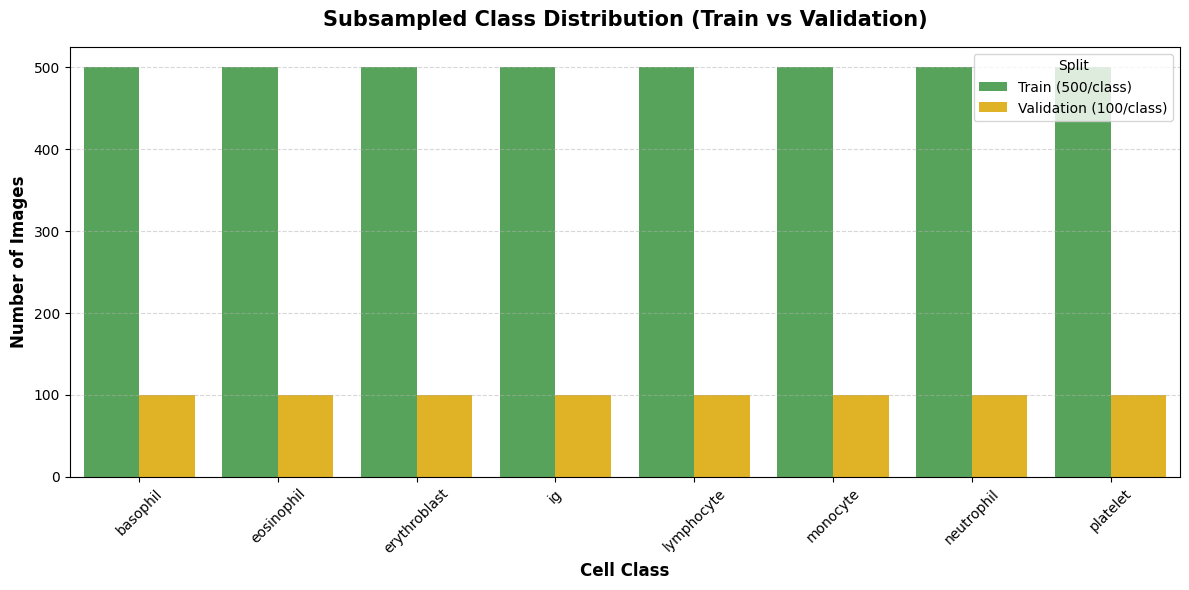

In [14]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

# Count occurrences of each class in training and validation sets
train_counts = train_df_sub['label'].value_counts().sort_index()
val_counts = val_df_sub['label'].value_counts().sort_index()

# Create a combined DataFrame for plotting
dist_df = pd.DataFrame({
    'Class': train_counts.index,
    'Train (500/class)': train_counts.values,
    'Validation (100/class)': val_counts.values
}).melt(id_vars='Class', var_name='Split', value_name='Count')

# Plotting the distributions side-by-side
plt.figure(figsize=(12, 6))
sns.barplot(data=dist_df, x='Class', y='Count', hue='Split', palette=['#4CAF50', '#FFC107'])

plt.title('Subsampled Class Distribution (Train vs Validation)', fontsize=15, fontweight='bold', pad=15)
plt.xlabel('Cell Class', fontsize=12, fontweight='bold')
plt.ylabel('Number of Images', fontsize=12, fontweight='bold')
plt.xticks(rotation=45)
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

In [15]:



# ==========================================
# MODEL 1 : BUILD & TRAIN BASIC CNN MODEL
# ==========================================
model1 = models.Sequential([
    # Input Scaling
    layers.Rescaling(1./255, input_shape=(IMG_SIZE[0], IMG_SIZE[1], 3)),

    # Data Augmentation
    data_augmentation,

    # Conv Block 1
    layers.Conv2D(32, (3, 3), padding='same', activation='relu'),
    layers.BatchNormalization(),
    layers.MaxPooling2D((2, 2)),

    # Conv Block 2
    layers.Conv2D(64, (3, 3), padding='same', activation='relu'),
    layers.BatchNormalization(),
    layers.MaxPooling2D((2, 2)),

    # Conv Block 3
    layers.Conv2D(128, (3, 3), padding='same', activation='relu'),
    layers.BatchNormalization(),
    layers.MaxPooling2D((2, 2)),

    # Dense Classifier
    layers.Flatten(),
    layers.Dense(128, activation='relu'),
    layers.Dropout(0.4),
    layers.Dense(num_classes, activation='softmax' if num_classes > 2 else 'sigmoid')
])

loss_fn = (
    tf.keras.losses.SparseCategoricalCrossentropy()
    if num_classes > 2
    else tf.keras.losses.BinaryCrossentropy()
)

model1.compile(
    optimizer='adam',
    loss=loss_fn,
    metrics=['accuracy']
)

model1.summary()

# Train Model
EPOCHS = 15
history1 = model1.fit(train_ds, validation_data=val_ds, epochs=15)

/usr/local/lib/python3.13/dist-packages/keras/src/layers/preprocessing/data_layer.py:95: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ rescaling (Rescaling)           │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ sequential (Sequential)         │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 128, 128, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 128, 128, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 64, 64, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 64, 64, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 64, 64, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 32, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 32, 32, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 32, 32, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 16, 16, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 32768)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │     4,194,432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 8)              │         1,032 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,289,608 (16.36 MB)

 Trainable params: 4,289,160 (16.36 MB)

 Non-trainable params: 448 (1.75 KB)

Epoch 1/15
125/125 ━━━━━━━━━━━━━━━━━━━━ 12s 34ms/step - accuracy: 0.2860 - loss: 2.4005 - val_accuracy: 0.1250 - val_loss: 27.1356
Epoch 2/15
125/125 ━━━━━━━━━━━━━━━━━━━━ 4s 31ms/step - accuracy: 0.3835 - loss: 1.6015 - val_accuracy: 0.1338 - val_loss: 34.4557
Epoch 3/15
125/125 ━━━━━━━━━━━━━━━━━━━━ 4s 32ms/step - accuracy: 0.4478 - loss: 1.3737 - val_accuracy: 0.2525 - val_loss: 12.1298
Epoch 4/15
125/125 ━━━━━━━━━━━━━━━━━━━━ 4s 32ms/step - accuracy: 0.5050 - loss: 1.2372 - val_accuracy: 0.2175 - val_loss: 3.9846
Epoch 5/15
125/125 ━━━━━━━━━━━━━━━━━━━━ 4s 31ms/step - accuracy: 0.5922 - loss: 1.0472 - val_accuracy: 0.6025 - val_loss: 1.1239
Epoch 6/15
125/125 ━━━━━━━━━━━━━━━━━━━━ 4s 32ms/step - accuracy: 0.6545 - loss: 0.8660 - val_accuracy: 0.6650 - val_loss: 1.3711
Epoch 7/15
125/125 ━━━━━━━━━━━━━━━━━━━━ 4s 32ms/step - accuracy: 0.6873 - loss: 0.8608 - val_accuracy: 0.1250 - val_loss: 303.6233
Epoch 8/15
125/125 ━━━━━━━━━━━━━━━━━━━━ 4s 31ms/step - accuracy: 0.6915 - loss: 0.8279 - va

In [16]:
# ==========================================
# MODEL 2 : IMPROVED CNN MODEL ARCHITECTURE
# ==========================================

model2 = models.Sequential([
    # Explicit Input Layer (Fixes Keras 3 Warning)
    layers.Input(shape=(IMG_SIZE[0], IMG_SIZE[1], 3)),

    # Input Normalization (0 to 1 range)
    layers.Rescaling(1./255),

    # Data Augmentation Block
    data_augmentation,

    # Conv Block 1
    layers.Conv2D(32, (3, 3), padding='same'),
    layers.BatchNormalization(),
    layers.Activation('relu'),
    layers.MaxPooling2D((2, 2)),

    # Conv Block 2
    layers.Conv2D(64, (3, 3), padding='same'),
    layers.BatchNormalization(),
    layers.Activation('relu'),
    layers.MaxPooling2D((2, 2)),

    # Conv Block 3
    layers.Conv2D(128, (3, 3), padding='same'),
    layers.BatchNormalization(),
    layers.Activation('relu'),
    layers.MaxPooling2D((2, 2)),

    # Conv Block 4 (Deeper feature extraction for cell morphology)
    layers.Conv2D(256, (3, 3), padding='same'),
    layers.BatchNormalization(),
    layers.Activation('relu'),
    layers.MaxPooling2D((2, 2)),

    # Dense Classifier
    layers.Flatten(),
    layers.Dense(256, activation='relu'),
    layers.BatchNormalization(),
    layers.Dropout(0.5),
    layers.Dense(num_classes, activation='softmax' if num_classes > 2 else 'sigmoid')
])

loss_fn = (
    tf.keras.losses.SparseCategoricalCrossentropy()
    if num_classes > 2
    else tf.keras.losses.BinaryCrossentropy()
)

# Use Learning Rate Scheduler / Reduced Initial LR
optimizer = tf.keras.optimizers.Adam(learning_rate=1e-3)

model2.compile(
    optimizer=optimizer,
    loss=loss_fn,
    metrics=['accuracy']
)

# Callbacks for better training performance
callbacks = [
    tf.keras.callbacks.ReduceLROnPlateau(
        monitor='val_loss', factor=0.5, patience=3, min_lr=1e-6, verbose=1
    ),
    tf.keras.callbacks.EarlyStopping(
        monitor='val_loss', patience=7, restore_best_weights=True, verbose=1
    )
]

model2.summary()

# Train Model for 25 Epochs with Early Stopping
history2 = model2.fit(train_ds, validation_data=val_ds, epochs=30, callbacks=callbacks)

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ rescaling_1 (Rescaling)         │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ sequential (Sequential)         │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 128, 128, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 128, 128, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation (Activation)         │ (None, 128, 128, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 64, 64, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 64, 64, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_4           │ (None, 64, 64, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_1 (Activation)       │ (None, 64, 64, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_4 (MaxPooling2D)  │ (None, 32, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 32, 32, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_5           │ (None, 32, 32, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_2 (Activation)       │ (None, 32, 32, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_5 (MaxPooling2D)  │ (None, 16, 16, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_6 (Conv2D)               │ (None, 16, 16, 256)    │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_6           │ (None, 16, 16, 256)    │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_3 (Activation)       │ (None, 16, 16, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_6 (MaxPooling2D)  │ (None, 8, 8, 256)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 16384)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 256)            │     4,194,560 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_7           │ (None, 256)            │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼─────────────

 Total params: 4,587,976 (17.50 MB)

 Trainable params: 4,586,504 (17.50 MB)

 Non-trainable params: 1,472 (5.75 KB)

Epoch 1/30
125/125 ━━━━━━━━━━━━━━━━━━━━ 9s 39ms/step - accuracy: 0.7690 - loss: 0.6929 - val_accuracy: 0.1250 - val_loss: 10.3049 - learning_rate: 0.0010
Epoch 2/30
125/125 ━━━━━━━━━━━━━━━━━━━━ 4s 35ms/step - accuracy: 0.8808 - loss: 0.3562 - val_accuracy: 0.1250 - val_loss: 12.3319 - learning_rate: 0.0010
Epoch 3/30
125/125 ━━━━━━━━━━━━━━━━━━━━ 4s 35ms/step - accuracy: 0.8920 - loss: 0.3210 - val_accuracy: 0.1250 - val_loss: 6.9127 - learning_rate: 0.0010
Epoch 4/30
125/125 ━━━━━━━━━━━━━━━━━━━━ 4s 35ms/step - accuracy: 0.9070 - loss: 0.2676 - val_accuracy: 0.4187 - val_loss: 2.3610 - learning_rate: 0.0010
Epoch 5/30
125/125 ━━━━━━━━━━━━━━━━━━━━ 4s 35ms/step - accuracy: 0.9293 - loss: 0.2145 - val_accuracy: 0.4900 - val_loss: 1.9143 - learning_rate: 0.0010
Epoch 6/30
125/125 ━━━━━━━━━━━━━━━━━━━━ 4s 35ms/step - accuracy: 0.9277 - loss: 0.2074 - val_accuracy: 0.4000 - val_loss: 3.3322 - learning_rate: 0.0010
Epoch 7/30
125/125 ━━━━━━━━━━━━━━━━━━━━ 4s 35ms/step - accuracy: 0.9340 - loss: 

In [17]:
# Calculate current splits based on loaded dataframes and raw dataset counts
total_raw_images = len(df)
train_count = len(train_df_sub)
val_count = len(val_df_sub)
test_count = total_raw_images - (train_count + val_count)

print(f"--- Actual Split Breakdown Used Now ---")
print(f"Train set:      {train_count} images ({train_count / total_raw_images * 100:.2f}% of total dataset)")
print(f"Validation set: {val_count} images ({val_count / total_raw_images * 100:.2f}% of total dataset)")
print(f"Remaining:      {test_count} images ({test_count / total_raw_images * 100:.2f}% of total dataset)")

--- Actual Split Breakdown Used Now ---
Train set:      4000 images (23.40% of total dataset)
Validation set: 800 images (4.68% of total dataset)
Remaining:      12292 images (71.92% of total dataset)


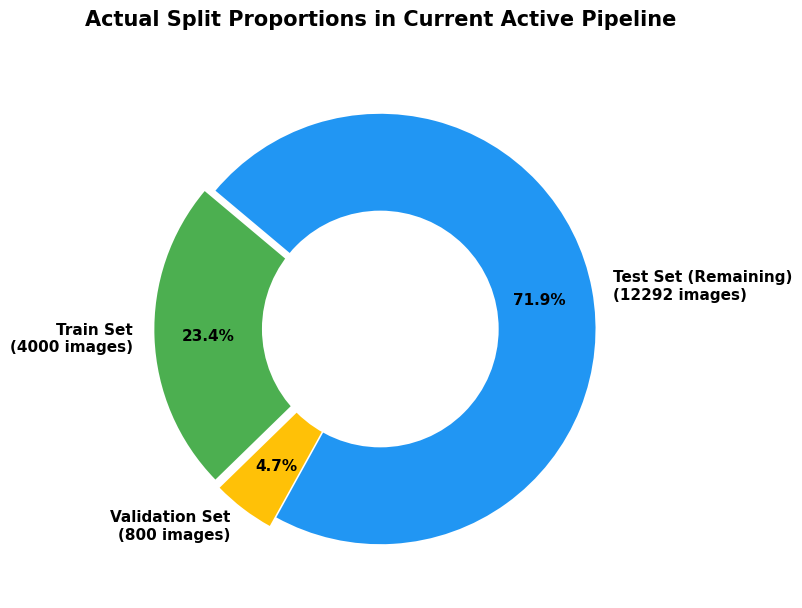

In [18]:
import matplotlib.pyplot as plt

# Calculate exact counts dynamically
total_raw_images = len(df)
train_count = len(train_df_sub)
val_count = len(val_df_sub)
test_count = total_raw_images - (train_count + val_count)

# Pie chart setup
labels = [
    f'Train Set\n({train_count} images)',
    f'Validation Set\n({val_count} images)',
    f'Test Set (Remaining)\n({test_count} images)'
]
sizes = [train_count, val_count, test_count]
colors = ['#4CAF50', '#FFC107', '#2196F3']
explode = (0.05, 0.05, 0)

plt.figure(figsize=(8, 8))
plt.pie(sizes, explode=explode, labels=labels, colors=colors, autopct='%1.1f%%',
        startangle=140, pctdistance=0.75, textprops={'fontsize': 11, 'fontweight': 'bold'})

# Transform to Donut Chart
centre_circle = plt.Circle((0,0),0.55,fc='white')
fig = plt.gcf()
fig.gca().add_artist(centre_circle)

plt.title('Actual Split Proportions in Current Active Pipeline', fontsize=15, fontweight='bold', pad=25)
plt.tight_layout()
plt.show()

In [19]:
# ==========================================
# MODEL 3 - TRANSFER LEARNING (EFFICIENTNETB0)
# ==========================================
import tensorflow as tf
from tensorflow.keras import layers, models

# 1. Load Pre-trained Base Model (Freeze initial weights)
base_model = tf.keras.applications.EfficientNetB0(
    include_top=False,
    weights='imagenet',
    input_shape=(IMG_SIZE[0], IMG_SIZE[1], 3)
)
base_model.trainable = False  # Freeze backbone features

# 2. Build Model Architecture
inputs = layers.Input(shape=(IMG_SIZE[0], IMG_SIZE[1], 3))
x = data_augmentation(inputs)

# Note: EfficientNet includes its own internal normalization layer.
x = base_model(x, training=False)
x = layers.GlobalAveragePooling2D()(x)
x = layers.BatchNormalization()(x)
x = layers.Dropout(0.4)(x)
x = layers.Dense(128, activation='relu')(x)
x = layers.Dropout(0.3)(x)

outputs = layers.Dense(num_classes, activation='softmax' if num_classes > 2 else 'sigmoid')(x)

model3 = models.Model(inputs=inputs, outputs=outputs, name="EfficientNetB0_Transfer")

# 3. Compile Model
loss_fn = (
    tf.keras.losses.SparseCategoricalCrossentropy()
    if num_classes > 2
    else tf.keras.losses.BinaryCrossentropy()
)

model3.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
    loss=loss_fn,
    metrics=['accuracy']
)

callbacks_m3 = [
    tf.keras.callbacks.ReduceLROnPlateau(
        monitor='val_loss', factor=0.5, patience=2, min_lr=1e-6, verbose=1
    ),
    tf.keras.callbacks.EarlyStopping(
        monitor='val_loss', patience=6, restore_best_weights=True, verbose=1
    )
]

print("--- Phase 1: Training Top Classifier Head ---")
history3_phase1 = model3.fit(
    train_ds,
    validation_data=val_ds,
    epochs=12,
    callbacks=callbacks_m3
)

# 4. Phase 2: Fine-Tuning Top Layers of Base Model
print("\n--- Phase 2: Fine-Tuning Deep Convolutional Feature Maps ---")
base_model.trainable = True

# Freeze bottom 100 layers and fine-tune top layers only
for layer in base_model.layers[:-30]:
    layer.trainable = False

# Recompile with a significantly lower learning rate to preserve pre-trained features
model3.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-4),
    loss=loss_fn,
    metrics=['accuracy']
)

history3_phase2 = model3.fit(
    train_ds,
    validation_data=val_ds,
    epochs=15,
    callbacks=callbacks_m3
)

# Combine history logs for seamless plotting later
class CombinedHistory:
    def __init__(self, h1, h2):
        self.history = {}
        for key in h1.history.keys():
            self.history[key] = h1.history[key] + h2.history[key]

history3 = CombinedHistory(history3_phase1, history3_phase2)

16705208/16705208 ━━━━━━━━━━━━━━━━━━━━ 3s 0us/step
--- Phase 1: Training Top Classifier Head ---
Epoch 1/12
125/125 ━━━━━━━━━━━━━━━━━━━━ 16s 41ms/step - accuracy: 0.5452 - loss: 1.3788 - val_accuracy: 0.7050 - val_loss: 0.9782 - learning_rate: 0.0010
Epoch 2/12
125/125 ━━━━━━━━━━━━━━━━━━━━ 3s 20ms/step - accuracy: 0.6858 - loss: 0.9343 - val_accuracy: 0.7700 - val_loss: 0.7168 - learning_rate: 0.0010
Epoch 3/12
125/125 ━━━━━━━━━━━━━━━━━━━━ 3s 21ms/step - accuracy: 0.7250 - loss: 0.8049 - val_accuracy: 0.7675 - val_loss: 0.6505 - learning_rate: 0.0010
Epoch 4/12
125/125 ━━━━━━━━━━━━━━━━━━━━ 3s 21ms/step - accuracy: 0.7280 - loss: 0.7857 - val_accuracy: 0.8025 - val_loss: 0.5404 - learning_rate: 0.0010
Epoch 5/12
125/125 ━━━━━━━━━━━━━━━━━━━━ 2s 20ms/step - accuracy: 0.7567 - loss: 0.7160 - val_accuracy: 0.8062 - val_loss: 0.5634 - learning_rate: 0.0010
Epoch 6/12
125/125 ━━━━━━━━━━━━━━━━━━━━ 3s 21ms/step - accuracy: 0.7625 - loss: 0.6848 - val_accuracy: 0.8087 - val_loss: 0.5232 - learni

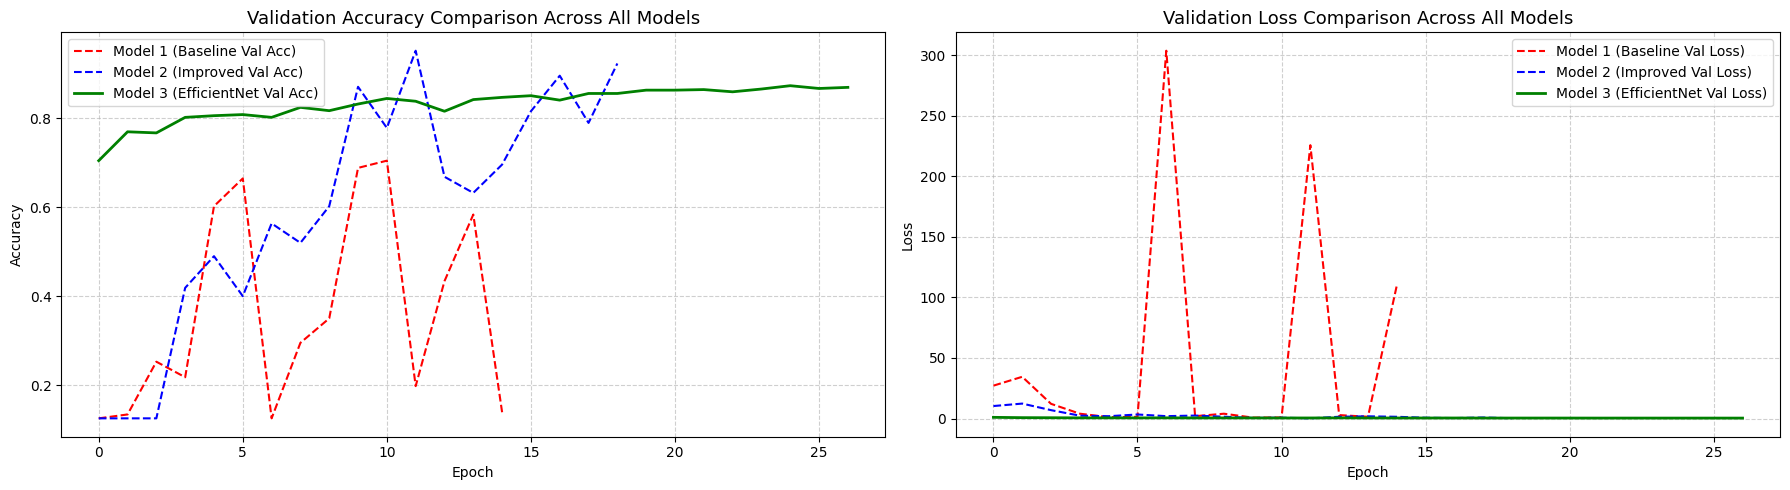

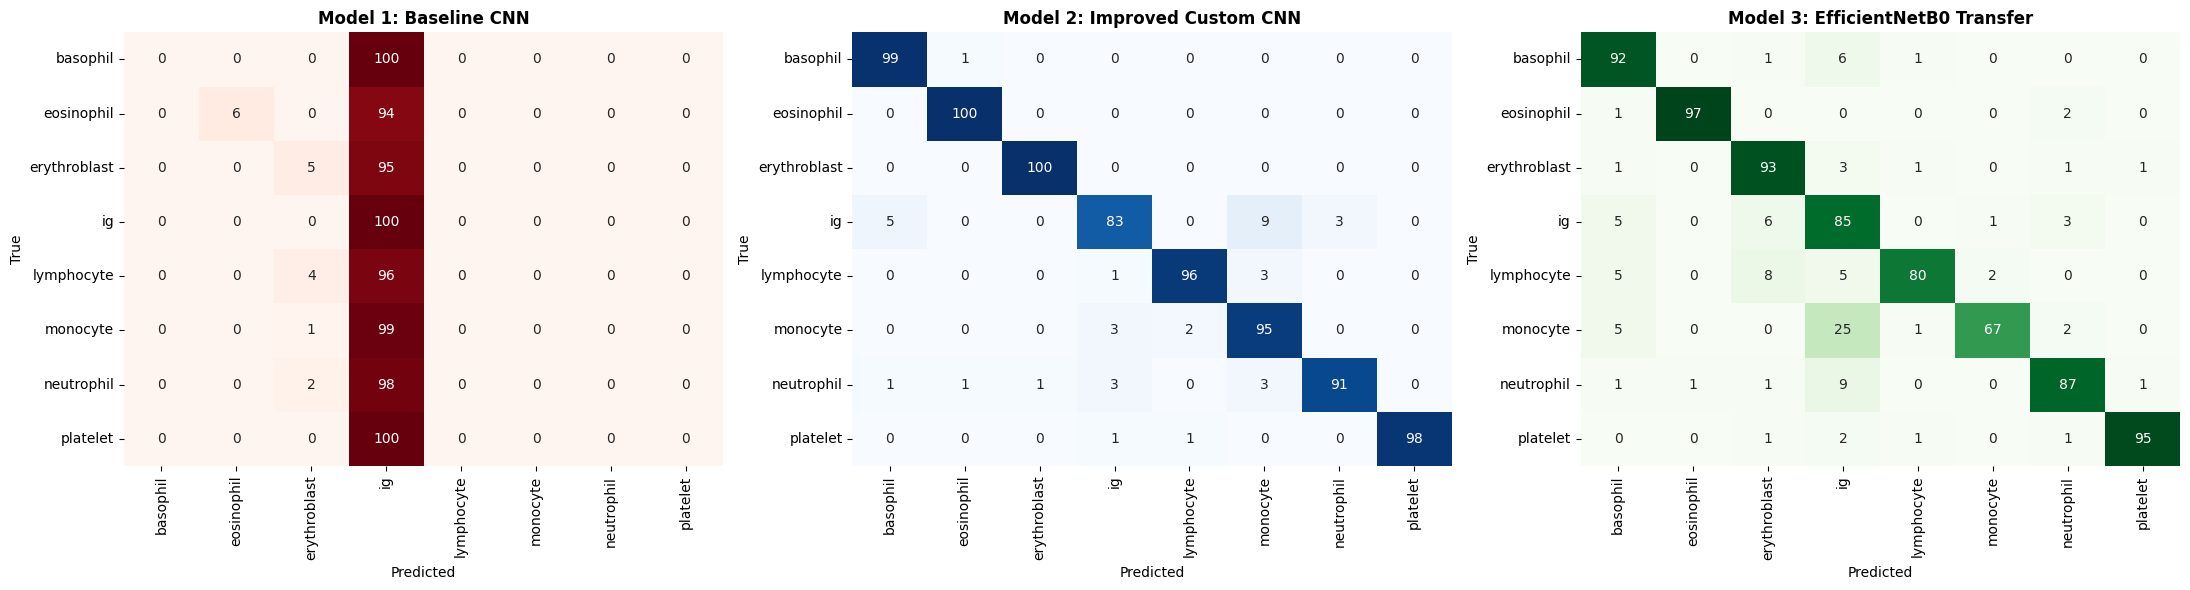

              MODEL 1 (BASELINE CNN) CLASSIFICATION REPORT
              precision    recall  f1-score   support

    basophil       0.00      0.00      0.00       100
  eosinophil       1.00      0.06      0.11       100
erythroblast       0.42      0.05      0.09       100
          ig       0.13      1.00      0.23       100
  lymphocyte       0.00      0.00      0.00       100
    monocyte       0.00      0.00      0.00       100
  neutrophil       0.00      0.00      0.00       100
    platelet       0.00      0.00      0.00       100

    accuracy                           0.14       800
   macro avg       0.19      0.14      0.05       800
weighted avg       0.19      0.14      0.05       800

          MODEL 2 (IMPROVED CUSTOM CNN) CLASSIFICATION REPORT
              precision    recall  f1-score   support

    basophil       0.94      0.99      0.97       100
  eosinophil       0.98      1.00      0.99       100
erythroblast       0.99      1.00      1.00       100
          i

In [21]:
# ==========================================
# CELL 5: 3-WAY MODEL PERFORMANCE COMPARISON
# ==========================================
import matplotlib.pyplot as plt
# 1. Overlay Training & Validation Curves for All 3 Models
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(18, 5))

# Accuracy Comparison Plot
ax1.plot(history1.history['val_accuracy'], label='Model 1 (Baseline Val Acc)', color='red', linestyle='--')
ax1.plot(history2.history['val_accuracy'], label='Model 2 (Improved Val Acc)', color='blue', linestyle='--')
ax1.plot(history3.history['val_accuracy'], label='Model 3 (EfficientNet Val Acc)', color='green', linewidth=2)
ax1.set_title('Validation Accuracy Comparison Across All Models', fontsize=13)
ax1.set_xlabel('Epoch')
ax1.set_ylabel('Accuracy')
ax1.legend()
ax1.grid(True, linestyle='--', alpha=0.6)

# Loss Comparison Plot
ax2.plot(history1.history['val_loss'], label='Model 1 (Baseline Val Loss)', color='red', linestyle='--')
ax2.plot(history2.history['val_loss'], label='Model 2 (Improved Val Loss)', color='blue', linestyle='--')
ax2.plot(history3.history['val_loss'], label='Model 3 (EfficientNet Val Loss)', color='green', linewidth=2)
ax2.set_title('Validation Loss Comparison Across All Models', fontsize=13)
ax2.set_xlabel('Epoch')
ax2.set_ylabel('Loss')
ax2.legend()
ax2.grid(True, linestyle='--', alpha=0.6)

plt.tight_layout()
plt.show()

# 2. Extract Validation Predictions for All 3 Models
def get_predictions(model_obj):
    y_true, y_pred = [], []
    for images, labels_batch in val_ds:
        preds = model_obj.predict(images, verbose=0)
        y_true.extend(labels_batch.numpy())
        if num_classes > 2:
            y_pred.extend(np.argmax(preds, axis=1))
        else:
            y_pred.extend((preds > 0.5).astype(int).flatten())
    return np.array(y_true), np.array(y_pred)

y_true1, y_pred1 = get_predictions(model1)
y_true2, y_pred2 = get_predictions(model2)
y_true3, y_pred3 = get_predictions(model3)

# 3. Plot Confusion Matrices Side-by-Side (3 Models)
fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(22, 6))

cm1 = confusion_matrix(y_true1, y_pred1)
sns.heatmap(cm1, annot=True, fmt='d', cmap='Reds',
            xticklabels=class_names, yticklabels=class_names, ax=ax1, cbar=False)
ax1.set_title('Model 1: Baseline CNN', fontsize=12, fontweight='bold')
ax1.set_xlabel('Predicted')
ax1.set_ylabel('True')

cm2 = confusion_matrix(y_true2, y_pred2)
sns.heatmap(cm2, annot=True, fmt='d', cmap='Blues',
            xticklabels=class_names, yticklabels=class_names, ax=ax2, cbar=False)
ax2.set_title('Model 2: Improved Custom CNN', fontsize=12, fontweight='bold')
ax2.set_xlabel('Predicted')
ax2.set_ylabel('True')

cm3 = confusion_matrix(y_true3, y_pred3)
sns.heatmap(cm3, annot=True, fmt='d', cmap='Greens',
            xticklabels=class_names, yticklabels=class_names, ax=ax3, cbar=False)
ax3.set_title('Model 3: EfficientNetB0 Transfer', fontsize=12, fontweight='bold')
ax3.set_xlabel('Predicted')
ax3.set_ylabel('True')

plt.tight_layout()
plt.show()

# 4. Print Classification Reports for All Models
print("=" * 65)
print("              MODEL 1 (BASELINE CNN) CLASSIFICATION REPORT")
print("=" * 65)
print(classification_report(y_true1, y_pred1, target_names=class_names, zero_division=0))

print("=" * 65)
print("          MODEL 2 (IMPROVED CUSTOM CNN) CLASSIFICATION REPORT")
print("=" * 65)
print(classification_report(y_true2, y_pred2, target_names=class_names, zero_division=0))

print("=" * 65)
print("        MODEL 3 (EFFICIENTNETB0 TRANSFER) CLASSIFICATION REPORT")
print("=" * 65)
print(classification_report(y_true3, y_pred3, target_names=class_names, zero_division=0))

### Scale Up: Training on the Entire Dataset with Dynamic Class Weights
Now that prototyping is complete, we scale our pipeline to train on **all available images** in the dataset. To counteract class imbalance, we dynamically calculate class weights using the training distribution and use them during model compilation and fitting.

In [22]:
import numpy as np
import tensorflow as tf
from tensorflow.keras import layers, models
from sklearn.model_selection import train_test_split
from sklearn.utils.class_weight import compute_class_weight

# 1. Split the ENTIRE dataset into Train (80%) and Validation (20%) while preserving class ratios
train_df_full, val_df_full = train_test_split(
    df,
    test_size=0.2,
    random_state=SEED,
    stratify=df['label']
)

print(f"Scaling Up to Complete Dataset:")
print(f"Full Dataset Training size: {len(train_df_full)}")
print(f"Full Dataset Validation size: {len(val_df_full)}")

# 2. Compute Class Weights to balance gradient updates during training
y_train_labels = train_df_full['label'].values
classes_present = np.unique(y_train_labels)

computed_weights = compute_class_weight(
    class_weight='balanced',
    classes=classes_present,
    y=y_train_labels
)

# Map the computed weights to the class indices for Keras
class_weight_dict = {class_to_idx[cls_name]: weight for cls_name, weight in zip(classes_present, computed_weights)}

print("\nComputed Dynamic Class Weights to Equalize Samples:")
for cls_name, idx in class_to_idx.items():
    print(f" - {cls_name} (Class {idx}): Weight factor = {class_weight_dict[idx]:.4f}")

# 3. Build Full Data Pipelines using dynamic loaders
def load_and_preprocess_full(path, label_name):
    img_raw = tf.io.read_file(path)
    img_tensor = tf.image.decode_image(img_raw, channels=3, expand_animations=False)
    img_tensor = tf.image.resize(img_tensor, IMG_SIZE)
    label_idx = tf.lookup.StaticHashTable(
        tf.lookup.KeyValueTensorInitializer(class_names, list(range(num_classes))),
        default_value=-1
    ).lookup(label_name)
    return img_tensor, label_idx

train_ds_full = tf.data.Dataset.from_tensor_slices((train_df_full['image_path'].values, train_df_full['label'].values))
train_ds_full = train_ds_full.map(load_and_preprocess_full, num_parallel_calls=tf.data.AUTOTUNE)

val_ds_full = tf.data.Dataset.from_tensor_slices((val_df_full['image_path'].values, val_df_full['label'].values))
val_ds_full = val_ds_full.map(load_and_preprocess_full, num_parallel_calls=tf.data.AUTOTUNE)

# Optimize pipeline performance for larger scale training
train_ds_full = train_ds_full.cache().shuffle(len(train_df_full)).batch(BATCH_SIZE).prefetch(buffer_size=tf.data.AUTOTUNE)
val_ds_full = val_ds_full.cache().batch(BATCH_SIZE).prefetch(buffer_size=tf.data.AUTOTUNE)

# 4. Rebuild EfficientNetB0 Transfer Model for Full-Scale Dataset training
base_model_full = tf.keras.applications.EfficientNetB0(
    include_top=False,
    weights='imagenet',
    input_shape=(IMG_SIZE[0], IMG_SIZE[1], 3)
)
base_model_full.trainable = False  # Start by training the top classifier first

inputs = layers.Input(shape=(IMG_SIZE[0], IMG_SIZE[1], 3))
x = data_augmentation(inputs)
x = base_model_full(x, training=False)
x = layers.GlobalAveragePooling2D()(x)
x = layers.BatchNormalization()(x)
x = layers.Dropout(0.4)(x)
x = layers.Dense(128, activation='relu')(x)
x = layers.Dropout(0.3)(x)
outputs = layers.Dense(num_classes, activation='softmax' if num_classes > 2 else 'sigmoid')(x)

model_full = models.Model(inputs=inputs, outputs=outputs, name="EfficientNetB0_FullDataset")

loss_fn = tf.keras.losses.SparseCategoricalCrossentropy() if num_classes > 2 else tf.keras.losses.BinaryCrossentropy()

model_full.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
    loss=loss_fn,
    metrics=['accuracy']
)

callbacks_full = [
    tf.keras.callbacks.ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=2, min_lr=1e-6, verbose=1),
    tf.keras.callbacks.EarlyStopping(monitor='val_loss', patience=5, restore_best_weights=True, verbose=1)
]

print("\n--- Phase 1: Training Classifier Head on Full Dataset ---")
history_full_phase1 = model_full.fit(
    train_ds_full,
    validation_data=val_ds_full,
    epochs=10,
    class_weight=class_weight_dict,
    callbacks=callbacks_full
)

# Unfreeze top layers of the feature extractor for high precision fine-tuning
print("\n--- Phase 2: Fine-tuning Base Network Feature Maps ---")
base_model_full.trainable = True
for layer in base_model_full.layers[:-30]:
    layer.trainable = False

model_full.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-4),
    loss=loss_fn,
    metrics=['accuracy']
)

history_full_phase2 = model_full.fit(
    train_ds_full,
    validation_data=val_ds_full,
    epochs=15,
    class_weight=class_weight_dict,
    callbacks=callbacks_full
)

Scaling Up to Complete Dataset:
Full Dataset Training size: 13673
Full Dataset Validation size: 3419

Computed Dynamic Class Weights to Equalize Samples:
 - basophil (Class 0): Weight factor = 1.7547
 - eosinophil (Class 1): Weight factor = 0.6853
 - erythroblast (Class 2): Weight factor = 1.3772
 - ig (Class 3): Weight factor = 0.7380
 - lymphocyte (Class 4): Weight factor = 1.7602
 - monocyte (Class 5): Weight factor = 1.5045
 - neutrophil (Class 6): Weight factor = 0.6418
 - platelet (Class 7): Weight factor = 0.9101

--- Phase 1: Training Classifier Head on Full Dataset ---
Epoch 1/10
428/428 ━━━━━━━━━━━━━━━━━━━━ 24s 27ms/step - accuracy: 0.6602 - loss: 1.0448 - val_accuracy: 0.8049 - val_loss: 0.5628 - learning_rate: 0.0010
Epoch 2/10
428/428 ━━━━━━━━━━━━━━━━━━━━ 9s 21ms/step - accuracy: 0.7517 - loss: 0.7365 - val_accuracy: 0.8435 - val_loss: 0.4387 - learning_rate: 0.0010
Epoch 3/10
428/428 ━━━━━━━━━━━━━━━━━━━━ 9s 21ms/step - accuracy: 0.7711 - loss: 0.6657 - val_accuracy: 0.838

### 1. Data Augmentation Visualization & Dataset Summary
Since TensorFlow's `tf.data` applies augmentation dynamically on-the-fly, each image is modified uniquely per epoch. Effectively, this increases our dataset variety infinitely. Below, we visualize how a sample from each class looks before and after applying our augmentation block (flips, rotations, zooms) and summarize the distribution of the full dataset scale.

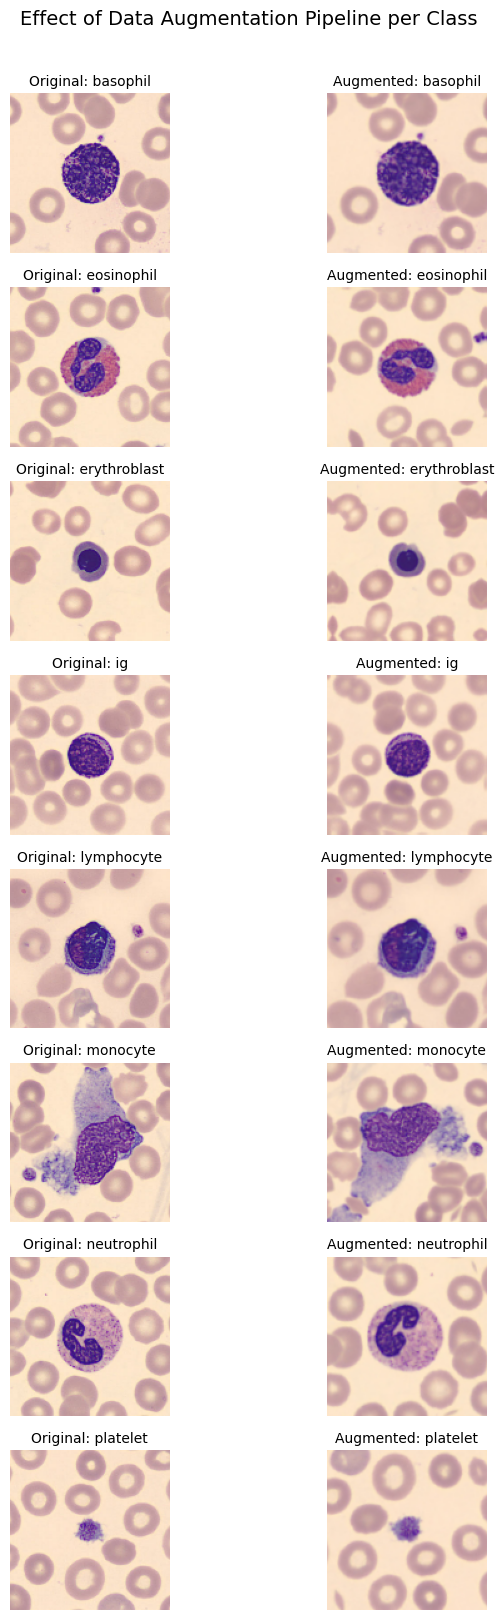

In [23]:
import matplotlib.pyplot as plt
import numpy as np
import tensorflow as tf

# Get one image per class to demonstrate augmentation
sample_images = []
sample_labels = []

for cls in class_names:
    path = df[df['label'] == cls]['image_path'].iloc[0]
    img_raw = tf.io.read_file(path)
    img_tensor = tf.image.decode_image(img_raw, channels=3, expand_animations=False)
    img_tensor = tf.image.resize(img_tensor, IMG_SIZE)
    sample_images.append(img_tensor)
    sample_labels.append(cls)

# Plot original vs augmented versions side-by-side
fig, axes = plt.subplots(len(class_names), 2, figsize=(8, 2 * len(class_names)))
for i, (img, label) in enumerate(zip(sample_images, sample_labels)):
    # Original
    axes[i, 0].imshow(img.numpy().astype('uint8'))
    axes[i, 0].set_title(f"Original: {label}", fontsize=10)
    axes[i, 0].axis('off')

    # Augmented
    augmented_img = data_augmentation(tf.expand_dims(img, 0), training=True)
    axes[i, 1].imshow(augmented_img[0].numpy().astype('uint8'))
    axes[i, 1].set_title(f"Augmented: {label}", fontsize=10)
    axes[i, 1].axis('off')

plt.suptitle("Effect of Data Augmentation Pipeline per Class", fontsize=14, y=1.01)
plt.tight_layout()
plt.show()

In [24]:
print(IMG_SIZE)
print(f"Full Dataset Training size: {len(train_df_full)}")
print(f"Full Dataset Validation size: {len(val_df_full)}")

(128, 128)
Full Dataset Training size: 13673
Full Dataset Validation size: 3419


### 2. Full Dataset Scale Training with Improved Custom CNN (Model 2)
Now, we reinitialize and fit **Model 2** on the full 13,673 training images, leveraging our dynamic class weights to combat imbalance, and validate on 3,419 images.

In [25]:
from tensorflow.keras import layers, models

# Re-build Model 2 architecture
model2_full = models.Sequential([
    layers.Input(shape=(IMG_SIZE[0], IMG_SIZE[1], 3)),
    layers.Rescaling(1./255),
    data_augmentation,

    # Conv Block 1
    layers.Conv2D(32, (3, 3), padding='same'),
    layers.BatchNormalization(),
    layers.Activation('relu'),
    layers.MaxPooling2D((2, 2)),

    # Conv Block 2
    layers.Conv2D(64, (3, 3), padding='same'),
    layers.BatchNormalization(),
    layers.Activation('relu'),
    layers.MaxPooling2D((2, 2)),

    # Conv Block 3
    layers.Conv2D(128, (3, 3), padding='same'),
    layers.BatchNormalization(),
    layers.Activation('relu'),
    layers.MaxPooling2D((2, 2)),

    # Conv Block 4
    layers.Conv2D(256, (3, 3), padding='same'),
    layers.BatchNormalization(),
    layers.Activation('relu'),
    layers.MaxPooling2D((2, 2)),

    # Classifier
    layers.Flatten(),
    layers.Dense(256, activation='relu'),
    layers.BatchNormalization(),
    layers.Dropout(0.5),
    layers.Dense(num_classes, activation='softmax' if num_classes > 2 else 'sigmoid')
])

model2_full.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
    loss=tf.keras.losses.SparseCategoricalCrossentropy() if num_classes > 2 else tf.keras.losses.BinaryCrossentropy(),
    metrics=['accuracy']
)

# Set up training parameters and fit on complete dataset
callbacks_m2_full = [
    tf.keras.callbacks.ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=3, min_lr=1e-6, verbose=1),
    tf.keras.callbacks.EarlyStopping(monitor='val_loss', patience=7, restore_best_weights=True, verbose=1)
]

print("Training Custom Model 2 on the Entire Dataset...")
history_m2_full = model2_full.fit(
    train_ds_full,
    validation_data=val_ds_full,
    epochs=25,
    class_weight=class_weight_dict,
    callbacks=callbacks_m2_full
)

Training Custom Model 2 on the Entire Dataset...
Epoch 1/25
428/428 ━━━━━━━━━━━━━━━━━━━━ 19s 37ms/step - accuracy: 0.8416 - loss: 0.4940 - val_accuracy: 0.4171 - val_loss: 2.3685 - learning_rate: 0.0010
Epoch 2/25
428/428 ━━━━━━━━━━━━━━━━━━━━ 15s 36ms/step - accuracy: 0.9152 - loss: 0.2571 - val_accuracy: 0.8406 - val_loss: 0.5557 - learning_rate: 0.0010
Epoch 3/25
428/428 ━━━━━━━━━━━━━━━━━━━━ 15s 35ms/step - accuracy: 0.9315 - loss: 0.2115 - val_accuracy: 0.7622 - val_loss: 0.8103 - learning_rate: 0.0010
Epoch 4/25
428/428 ━━━━━━━━━━━━━━━━━━━━ 15s 35ms/step - accuracy: 0.9411 - loss: 0.1758 - val_accuracy: 0.4191 - val_loss: 2.8406 - learning_rate: 0.0010
Epoch 5/25
427/428 ━━━━━━━━━━━━━━━━━━━━ 0s 34ms/step - accuracy: 0.9386 - loss: 0.1808
Epoch 5: ReduceLROnPlateau reducing learning rate to 0.0005000000237487257.
428/428 ━━━━━━━━━━━━━━━━━━━━ 15s 35ms/step - accuracy: 0.9449 - loss: 0.1606 - val_accuracy: 0.7145 - val_loss: 0.9417 - learning_rate: 0.0010
Epoch 6/25
428/428 ━━━━━━━━━━

### 3. Evaluation of Model 2 on the Full Dataset
Let's plot the training curves, confusion matrix, and print a classification report to assess performance on the complete dataset.

NameError: name 'history_m2_full' is not defined

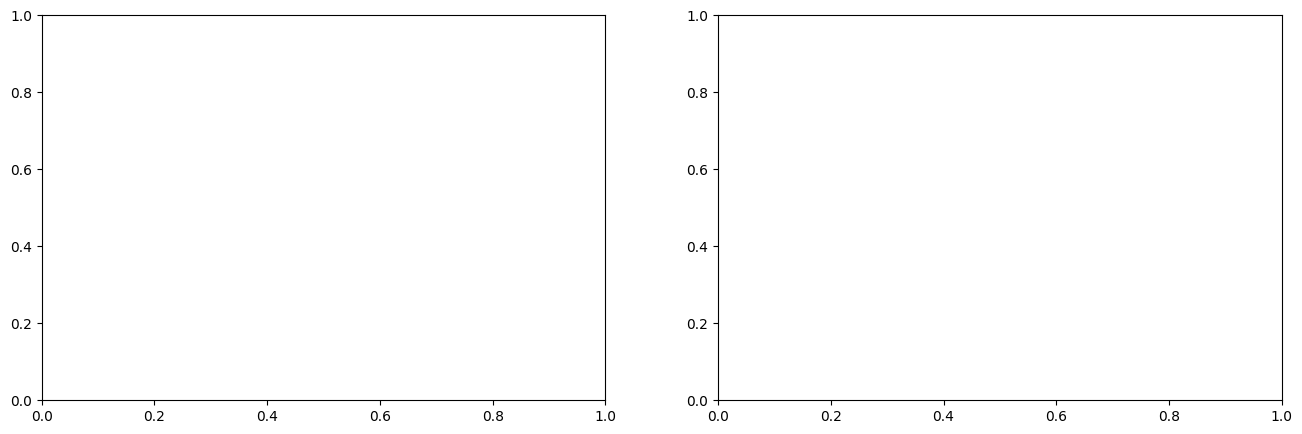

In [3]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import classification_report, confusion_matrix

# 1. Plot Accuracy & Loss Curves
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 5))

ax1.plot(history_m2_full.history['accuracy'], label='Train Accuracy', color='blue')
ax1.plot(history_m2_full.history['val_accuracy'], label='Val Accuracy', color='orange', linestyle='--')
ax1.set_title('Full Dataset Training & Validation Accuracy (Model 2)', fontsize=12, fontweight='bold')
ax1.set_xlabel('Epoch')
ax1.set_ylabel('Accuracy')
ax1.legend()
ax1.grid(True, alpha=0.5)

ax2.plot(history_m2_full.history['loss'], label='Train Loss', color='blue')
ax2.plot(history_m2_full.history['val_loss'], label='Val Loss', color='orange', linestyle='--')
ax2.set_title('Full Dataset Training & Validation Loss (Model 2)', fontsize=12, fontweight='bold')
ax2.set_xlabel('Epoch')
ax2.set_ylabel('Loss')
ax2.legend()
ax2.grid(True, alpha=0.5)

plt.tight_layout()
plt.show()

# 2. Extract Validation Predictions
y_true_full, y_pred_full = [], []
for images, labels_batch in val_ds_full:
    preds = model2_full.predict(images, verbose=0)
    y_true_full.extend(labels_batch.numpy())
    y_pred_full.extend(np.argmax(preds, axis=1))

y_true_full = np.array(y_true_full)
y_pred_full = np.array(y_pred_full)

# 3. Plot Confusion Matrix
plt.figure(figsize=(10, 8))
cm_full = confusion_matrix(y_true_full, y_pred_full)
sns.heatmap(cm_full, annot=True, fmt='d', cmap='Blues',
            xticklabels=class_names, yticklabels=class_names)
plt.title('Full Scale Validation Confusion Matrix (Model 2)', fontsize=14, fontweight='bold')
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.tight_layout()
plt.show()

# 4. Classification Report
print("=" * 65)
print("       MODEL 2 FULL DATASET EVALUATION REPORT")
print("=" * 65)
print(classification_report(y_true_full, y_pred_full, target_names=class_names))

### 4. Feature Selection & Image Resolution Analysis

#### 1. Is Feature Selection or Feature Engineering required for medical cell images?
* **CNNs as Automated Feature Extractors**: Traditional hand-crafted feature engineering (like extraction of Sobel/Canny edges, cell contour features, or color histograms) is largely redundant because Deep CNNs dynamically optimize their convolutional filters to capture textures, cell boundaries, and color intensities.
* **Crucial Visual Preprocessing**: Instead of manual engineering, maintaining **data augmentation** (flips, rotations, and slight zooms) is vital. Medical smears vary arbitrarily in rotation and translation depending on how the microscope slide was positioned; training with random transformations ensures rotation-invariant features.

#### 2. Is 128x128 sufficient or should we try original dimensions?
* **Sufficiency**: `128x128` resolution is an excellent, standard baseline. It captures overall cell morphology, nucleus-to-cytoplasm ratio, and color profiles while being extremely computationally efficient.
* **Fine Grained Details**: Peripheral blood smear classification (like distinguishing immature granulocytes `ig` or recognizing subtle nuclear segmentations in `neutrophil` types) heavily relies on **intranuclear textures** (chromatin structure). Downsampling to `128x128` can smudge these intricate features.
* **Comparison to Higher Resolutions (e.g., 224x224)**: Training at original size (typically 360x363 or larger) drastically increases VRAM consumption and slows training speeds. A sweet spot is **`224x224`**, which is the native input size for pre-trained networks like EfficientNet and allows CNN kernels to resolve finer structural features of the cell nucleus.

### 5. Running Model 2 at 224x224 Resolution

To analyze how the higher image resolution impacts classification performance, we will update our `IMG_SIZE` parameter to `(224, 224)`, reconstruct our full scale train and validation pipelines, and train Model 2 on the larger resolution.

In [27]:
import tensorflow as tf

# Update target image size to 224x224
IMG_SIZE_224 = (224, 224)

# 1. Map full dataset load with 224x224 resolution
def load_and_preprocess_224(path, label_name):
    img_raw = tf.io.read_file(path)
    img_tensor = tf.image.decode_image(img_raw, channels=3, expand_animations=False)
    img_tensor = tf.image.resize(img_tensor, IMG_SIZE_224)
    label_idx = tf.lookup.StaticHashTable(
        tf.lookup.KeyValueTensorInitializer(class_names, list(range(num_classes))),
        default_value=-1
    ).lookup(label_name)
    return img_tensor, label_idx

train_ds_full_224 = tf.data.Dataset.from_tensor_slices((train_df_full['image_path'].values, train_df_full['label'].values))
train_ds_full_224 = train_ds_full_224.map(load_and_preprocess_224, num_parallel_calls=tf.data.AUTOTUNE)

val_ds_full_224 = tf.data.Dataset.from_tensor_slices((val_df_full['image_path'].values, val_df_full['label'].values))
val_ds_full_224 = val_ds_full_224.map(load_and_preprocess_224, num_parallel_calls=tf.data.AUTOTUNE)

# Apply performance optimizations
train_ds_full_224 = train_ds_full_224.cache().shuffle(len(train_df_full)).batch(BATCH_SIZE).prefetch(buffer_size=tf.data.AUTOTUNE)
val_ds_full_224 = val_ds_full_224.cache().batch(BATCH_SIZE).prefetch(buffer_size=tf.data.AUTOTUNE)

# 2. Separate Data Augmentation Block for 224x224 inputs
data_augmentation_224 = tf.keras.Sequential([
    tf.keras.layers.RandomFlip("horizontal_and_vertical"),
    tf.keras.layers.RandomRotation(0.2),
    tf.keras.layers.RandomZoom(0.1),
])

#### Rebuilding Model 2 for 224x224 Resolution Input

In [28]:
from tensorflow.keras import layers, models

# Re-build Model 2 structure adjusting input shape
model2_224 = models.Sequential([
    layers.Input(shape=(IMG_SIZE_224[0], IMG_SIZE_224[1], 3)),
    layers.Rescaling(1./255),
    data_augmentation_224,

    # Conv Block 1
    layers.Conv2D(32, (3, 3), padding='same'),
    layers.BatchNormalization(),
    layers.Activation('relu'),
    layers.MaxPooling2D((2, 2)),

    # Conv Block 2
    layers.Conv2D(64, (3, 3), padding='same'),
    layers.BatchNormalization(),
    layers.Activation('relu'),
    layers.MaxPooling2D((2, 2)),

    # Conv Block 3
    layers.Conv2D(128, (3, 3), padding='same'),
    layers.BatchNormalization(),
    layers.Activation('relu'),
    layers.MaxPooling2D((2, 2)),

    # Conv Block 4
    layers.Conv2D(256, (3, 3), padding='same'),
    layers.BatchNormalization(),
    layers.Activation('relu'),
    layers.MaxPooling2D((2, 2)),

    # Classifier
    layers.Flatten(),
    layers.Dense(256, activation='relu'),
    layers.BatchNormalization(),
    layers.Dropout(0.5),
    layers.Dense(num_classes, activation='softmax' if num_classes > 2 else 'sigmoid')
])

model2_224.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
    loss=tf.keras.losses.SparseCategoricalCrossentropy() if num_classes > 2 else tf.keras.losses.BinaryCrossentropy(),
    metrics=['accuracy']
)

# Train the 224x224 Model
print("Training Custom Model 2 at 224x224 Resolution...")
history_m2_224 = model2_224.fit(
    train_ds_full_224,
    validation_data=val_ds_full_224,
    epochs=25,
    class_weight=class_weight_dict,
    callbacks=callbacks_m2_full
)

Training Custom Model 2 at 224x224 Resolution...
Epoch 1/25
428/428 ━━━━━━━━━━━━━━━━━━━━ 58s 118ms/step - accuracy: 0.8420 - loss: 0.4823 - val_accuracy: 0.2164 - val_loss: 2.7635 - learning_rate: 0.0010
Epoch 2/25
428/428 ━━━━━━━━━━━━━━━━━━━━ 49s 114ms/step - accuracy: 0.9134 - loss: 0.2551 - val_accuracy: 0.7713 - val_loss: 0.7603 - learning_rate: 0.0010
Epoch 3/25
427/428 ━━━━━━━━━━━━━━━━━━━━ 0s 109ms/step - accuracy: 0.9266 - loss: 0.2116
Epoch 3: ReduceLROnPlateau reducing learning rate to 0.0005000000237487257.
428/428 ━━━━━━━━━━━━━━━━━━━━ 49s 114ms/step - accuracy: 0.9332 - loss: 0.1964 - val_accuracy: 0.5543 - val_loss: 2.5548 - learning_rate: 0.0010
Epoch 4/25
428/428 ━━━━━━━━━━━━━━━━━━━━ 49s 114ms/step - accuracy: 0.9560 - loss: 0.1276 - val_accuracy: 0.7569 - val_loss: 1.0912 - learning_rate: 5.0000e-04
Epoch 5/25
428/428 ━━━━━━━━━━━━━━━━━━━━ 49s 114ms/step - accuracy: 0.9588 - loss: 0.1192 - val_accuracy: 0.6587 - val_loss: 2.5773 - learning_rate: 5.0000e-04
Epoch 6/25
427/

#### Plotting Performance and Evaluational Curves for 224x224 Model 2

NameError: name 'history_m2_224' is not defined

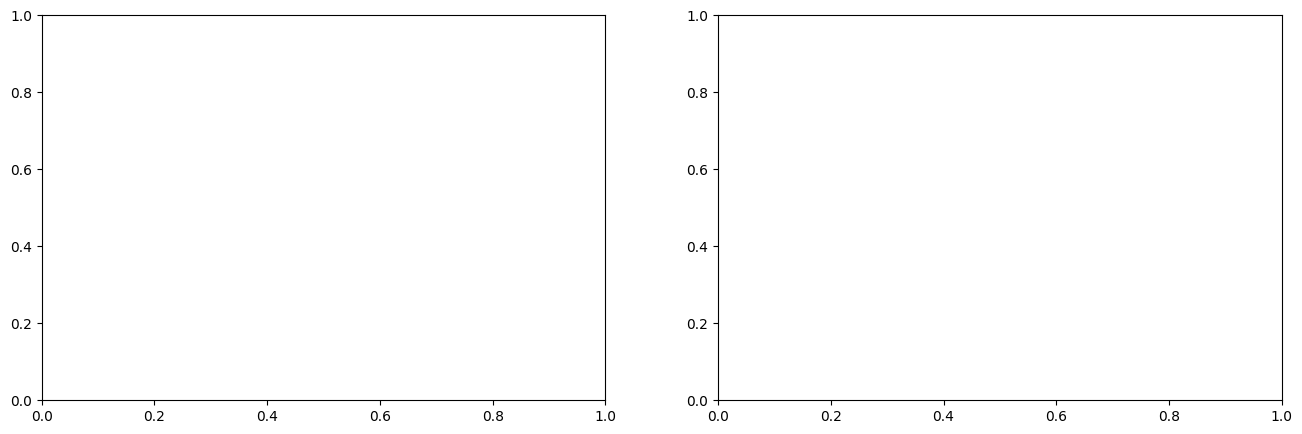

In [2]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
from sklearn.metrics import classification_report, confusion_matrix

# 1. Plot Accuracy & Loss Curves
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 5))

ax1.plot(history_m2_224.history['accuracy'], label='Train Accuracy', color='green')
ax1.plot(history_m2_224.history['val_accuracy'], label='Val Accuracy', color='darkorange', linestyle='--')
ax1.set_title('Training & Validation Accuracy (Model 2 - 224x224)', fontsize=12, fontweight='bold')
ax1.set_xlabel('Epoch')
ax1.set_ylabel('Accuracy')
ax1.legend()
ax1.grid(True, alpha=0.5)

ax2.plot(history_m2_224.history['loss'], label='Train Loss', color='green')
ax2.plot(history_m2_224.history['val_loss'], label='Val Loss', color='darkorange', linestyle='--')
ax2.set_title('Training & Validation Loss (Model 2 - 224x224)', fontsize=12, fontweight='bold')
ax2.set_xlabel('Epoch')
ax2.set_ylabel('Loss')
ax2.legend()
ax2.grid(True, alpha=0.5)

plt.tight_layout()
plt.show()

# 2. Extract Validation Predictions
y_true_224, y_pred_224 = [], []
for images, labels_batch in val_ds_full_224:
    preds = model2_224.predict(images, verbose=0)
    y_true_224.extend(labels_batch.numpy())
    y_pred_224.extend(np.argmax(preds, axis=1))

y_true_224 = np.array(y_true_224)
y_pred_224 = np.array(y_pred_224)

# 3. Plot Confusion Matrix
plt.figure(figsize=(10, 8))
cm_224 = confusion_matrix(y_true_224, y_pred_224)
sns.heatmap(cm_224, annot=True, fmt='d', cmap='Greens',
            xticklabels=class_names, yticklabels=class_names)
plt.title('Validation Confusion Matrix (Model 2 - 224x224)', fontsize=14, fontweight='bold')
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.tight_layout()
plt.show()

# 4. Classification Report
print("=" * 65)
print("       MODEL 2 224x224 DATASET EVALUATION REPORT")
print("=" * 65)
print(classification_report(y_true_224, y_pred_224, target_names=class_names))

### 6. Final Comparisons

#### Comparison 1: Model 2 vs. EfficientNetB0 (128x128 on Full Dataset)
We compare the validation performance of our Improved Custom CNN (Model 2) trained on the full dataset with the Transfer Learning model (EfficientNetB0) trained on the full dataset, both utilizing $128 \times 128$ resolution inputs.

#### Comparison 2: Resolution & Subsampling Impact on Model 2
We compare Model 2 under three scenarios:
1. Prototyped Subsampled Dataset ($128 \times 128$ resolution)
2. Full Dataset ($128 \times 128$ resolution)
3. Full Dataset ($224 \times 224$ resolution)

We will also construct a comprehensive comparison of Precision, Recall, and F1-Scores across all three Model 2 experiments.

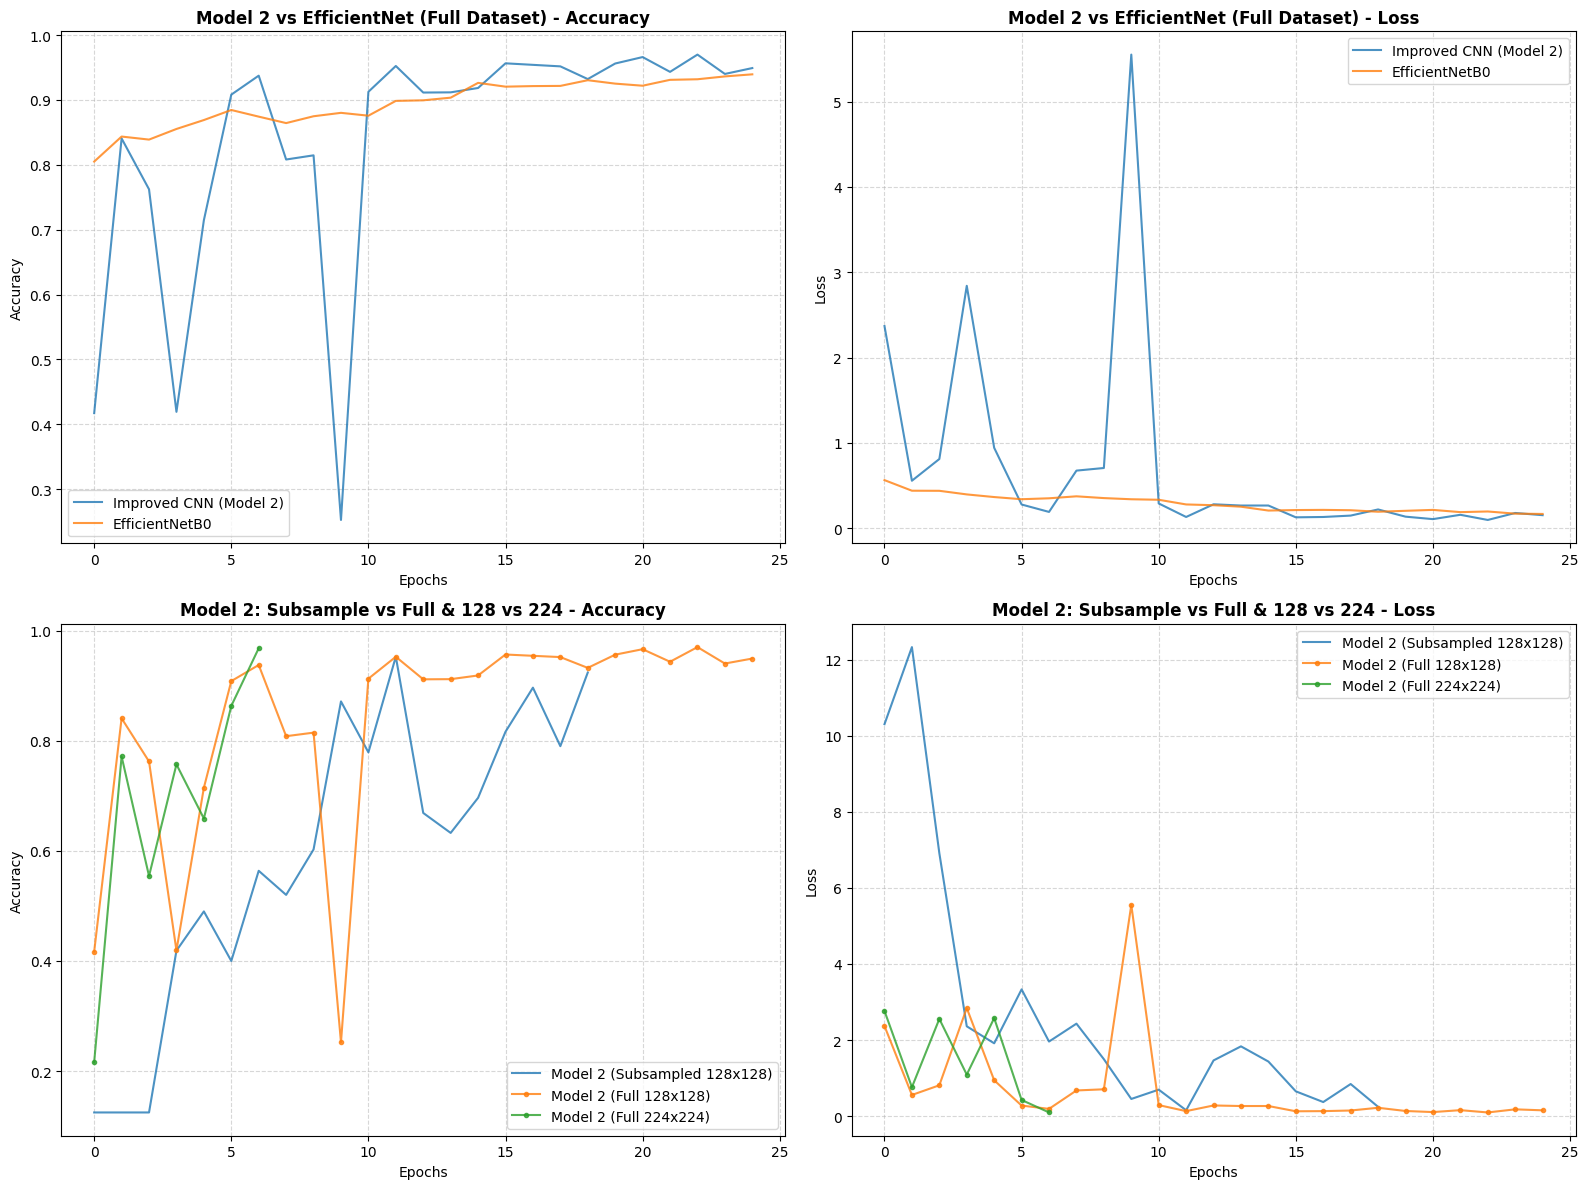

In [30]:
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np

# =========================================================================
# CLEANED UP VISUALIZATION: Model Comparisons & Size Impact
# =========================================================================

def plot_history_comparison(histories_dict, title, ax_acc, ax_loss):
    """Helper function to avoid repetitive plotting code."""
    has_labels = False
    for label, history in histories_dict.items():
        if history:
            has_labels = True
            # Handle concatenated histories (e.g., EfficientNet 2-phase training)
            if isinstance(history, list):
                acc, loss = history[0] + history[1], history[2] + history[3]
            else:
                acc = history.history.get('val_accuracy', [])
                loss = history.history.get('val_loss', [])

            ax_acc.plot(acc, label=label, marker='.' if 'Full' in label else '', alpha=0.8)
            ax_loss.plot(loss, label=label, marker='.' if 'Full' in label else '', alpha=0.8)

    ax_acc.set_title(f'{title} - Accuracy', fontsize=12, fontweight='bold')
    ax_acc.set_xlabel('Epochs')
    ax_acc.set_ylabel('Accuracy')
    if has_labels:
        ax_acc.legend()
    ax_acc.grid(True, linestyle='--', alpha=0.5)

    ax_loss.set_title(f'{title} - Loss', fontsize=12, fontweight='bold')
    ax_loss.set_xlabel('Epochs')
    ax_loss.set_ylabel('Loss')
    if has_labels:
        ax_loss.legend()
    ax_loss.grid(True, linestyle='--', alpha=0.5)

fig, axes = plt.subplots(2, 2, figsize=(16, 12))

# 1. Model 2 vs EfficientNetB0 (Full Dataset @ 128x128)
eff_history = None
if 'history_full_phase1' in globals() and 'history_full_phase2' in globals():
    eff_history = [
        history_full_phase1.history['val_accuracy'], history_full_phase2.history['val_accuracy'],
        history_full_phase1.history['val_loss'], history_full_phase2.history['val_loss']
    ]

comp1_hists = {
    'Improved CNN (Model 2)': history_m2_full if 'history_m2_full' in globals() else None,
    'EfficientNetB0': eff_history
}
plot_history_comparison(comp1_hists, 'Model 2 vs EfficientNet (Full Dataset)', axes[0,0], axes[0,1])

# 2. Improved CNN (Model 2): Impact of Dataset Size and Resolution
comp2_hists = {
    'Model 2 (Subsampled 128x128)': history2 if 'history2' in globals() else None,
    'Model 2 (Full 128x128)': history_m2_full if 'history_m2_full' in globals() else None,
    'Model 2 (Full 224x224)': history_m2_224 if 'history_m2_224' in globals() else None
}
plot_history_comparison(comp2_hists, 'Model 2: Subsample vs Full & 128 vs 224', axes[1,0], axes[1,1])

plt.tight_layout()
plt.show()

In [31]:
# =========================================================================
# PRECISION & RECALL TABLES FOR THE 3 SCENARIOS (MODEL 2)
# =========================================================================

def get_metrics_dict(y_true, y_pred, class_names):
    report = classification_report(y_true, y_pred, target_names=class_names, output_dict=True)
    return report

metrics_data = []

# Scenario 1: Subsampled (128x128)
if 'y_true2' in globals() and 'y_pred2' in globals():
    r1 = get_metrics_dict(y_true2, y_pred2, class_names)
    for cls in class_names:
        metrics_data.append({
            'Class': cls,
            'Experiment': 'M2 Subsample (128x128)',
            'Precision': r1[cls]['precision'],
            'Recall': r1[cls]['recall'],
            'F1-Score': r1[cls]['f1-score']
        })

# Scenario 2: Full Dataset (128x128)
if 'y_true_full' in globals() and 'y_pred_full' in globals():
    r2 = get_metrics_dict(y_true_full, y_pred_full, class_names)
    for cls in class_names:
        metrics_data.append({
            'Class': cls,
            'Experiment': 'M2 Full (128x128)',
            'Precision': r2[cls]['precision'],
            'Recall': r2[cls]['recall'],
            'F1-Score': r2[cls]['f1-score']
        })

# Scenario 3: Full Dataset (224x224)
if 'y_true_224' in globals() and 'y_pred_224' in globals():
    r3 = get_metrics_dict(y_true_224, y_pred_224, class_names)
    for cls in class_names:
        metrics_data.append({
            'Class': cls,
            'Experiment': 'M2 Full (224x224)',
            'Precision': r3[cls]['precision'],
            'Recall': r3[cls]['recall'],
            'F1-Score': r3[cls]['f1-score']
        })

if metrics_data:
    metrics_df = pd.DataFrame(metrics_data)
    pivot_df = metrics_df.pivot(index='Class', columns='Experiment', values=['Precision', 'Recall', 'F1-Score'])
    # Reorder columns logically
    columns_order = [
        ('Precision', 'M2 Subsample (128x128)'), ('Precision', 'M2 Full (128x128)'), ('Precision', 'M2 Full (224x224)'),
        ('Recall', 'M2 Subsample (128x128)'), ('Recall', 'M2 Full (128x128)'), ('Recall', 'M2 Full (224x224)'),
        ('F1-Score', 'M2 Subsample (128x128)'), ('F1-Score', 'M2 Full (128x128)'), ('F1-Score', 'M2 Full (224x224)')
    ]
    # Drop column groups if some keys are missing (e.g. if 224x224 has not finished execution yet)
    actual_columns = [col for col in columns_order if col in pivot_df.columns]
    pivot_df = pivot_df[actual_columns]
    display(pivot_df.round(3))
else:
    print("Metrics variable pairs are missing or some experiments haven't completed running yet.")

/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


Precision                                      \
Experiment   M2 Subsample (128x128) M2 Full (128x128) M2 Full (224x224)   
Class                                                                     
basophil                      0.943             0.917             0.000   
eosinophil                    0.980             0.998             1.000   
erythroblast                  0.990             0.984             0.000   
ig                            0.912             0.933             0.642   
lymphocyte                    0.970             0.995             0.347   
monocyte                      0.864             0.911             0.559   
neutrophil                    0.968             0.986             0.941   
platelet                      1.000             1.000             0.161   

                             Recall                                      \
Experiment   M2 Subsample (128x128) M2 Full (128x128) M2 Full (224x224)   
Class                                                                     
basophil                       0.99             0.996             0.000   
eosinophil                     1.00             0.997             0.061   
erythroblast                   1.00             0.990             0.000   
ig                             0.83             0.960             0.199   
lymphocyte                     0.96             0.877             0.337   
monocyte                       0.95             0.901             0.067   
neutrophil                     0.91             0.977             0.024   
platelet                       0.98             0.998             1.000   

                           F1-Score                                      
Experiment   M2 Subsample (128x128) M2 Full (128x128) M2 Full (224x224)  
Class                                                                    
basophil                      0.966             0.955             0.000  
eosinophil                    0.990             0.998             0.115  
erythroblast                  0.995             0.987             0.000  
ig                            0.869             0.946             0.303  
lymphocyte                    0.965             0.932             0.342  
monocyte                      0.905             0.906             0.119  
neutrophil                    0.938             0.982             0.047  
platelet                      0.990             0.999             0.278

### 7. Resolving Resolution Scale-up with Global Average Pooling
By replacing the rigid `Flatten()` layer with a `GlobalAveragePooling2D()` layer, we decouple the final classification layer from the raw pixel input size. This dramatically cuts parameter bloat and improves generalizability at higher resolutions like 224x224.

In [1]:
from tensorflow.keras import layers, models
import tensorflow as tf

# Re-architecting Model 2 using Global Average Pooling
model2_224_gap = models.Sequential([
    layers.Input(shape=(IMG_SIZE_224[0], IMG_SIZE_224[1], 3)),
    layers.Rescaling(1./255),
    data_augmentation_224,

    # Conv Block 1
    layers.Conv2D(32, (3, 3), padding='same'),
    layers.BatchNormalization(),
    layers.Activation('relu'),
    layers.MaxPooling2D((2, 2)),

    # Conv Block 2
    layers.Conv2D(64, (3, 3), padding='same'),
    layers.BatchNormalization(),
    layers.Activation('relu'),
    layers.MaxPooling2D((2, 2)),

    # Conv Block 3
    layers.Conv2D(128, (3, 3), padding='same'),
    layers.BatchNormalization(),
    layers.Activation('relu'),
    layers.MaxPooling2D((2, 2)),

    # Conv Block 4
    layers.Conv2D(256, (3, 3), padding='same'),
    layers.BatchNormalization(),
    layers.Activation('relu'),
    layers.MaxPooling2D((2, 2)),

    # Dynamic Reduction instead of Flatten
    layers.GlobalAveragePooling2D(),

    # Classifier Head
    layers.Dense(256, activation='relu'),
    layers.BatchNormalization(),
    layers.Dropout(0.4),
    layers.Dense(num_classes, activation='softmax' if num_classes > 2 else 'sigmoid')
])

model2_224_gap.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
    loss=tf.keras.losses.SparseCategoricalCrossentropy() if num_classes > 2 else tf.keras.losses.BinaryCrossentropy(),
    metrics=['accuracy']
)

model2_224_gap.summary()

# Train revised 224x224 model
print("Training GAP-Optimized Custom Model 2 at 224x224...")
history_m2_224_gap = model2_224_gap.fit(
    train_ds_full_224,
    validation_data=val_ds_full_224,
    epochs=25,
    class_weight=class_weight_dict,
    callbacks=callbacks_m2_full
)

NameError: name 'IMG_SIZE_224' is not defined

### Training Model 2 with GAP at 128x128 on the Full Dataset
We will define a 128x128 GAP-based version of Model 2 and train it on the full dataset to acquire the validation performance statistics.

In [33]:
from tensorflow.keras import layers, models
import tensorflow as tf

# Build Model 2 with GAP for 128x128 inputs
model2_128_gap = models.Sequential([
    layers.Input(shape=(IMG_SIZE[0], IMG_SIZE[1], 3)),
    layers.Rescaling(1./255),
    data_augmentation,

    # Conv Block 1
    layers.Conv2D(32, (3, 3), padding='same'),
    layers.BatchNormalization(),
    layers.Activation('relu'),
    layers.MaxPooling2D((2, 2)),

    # Conv Block 2
    layers.Conv2D(64, (3, 3), padding='same'),
    layers.BatchNormalization(),
    layers.Activation('relu'),
    layers.MaxPooling2D((2, 2)),

    # Conv Block 3
    layers.Conv2D(128, (3, 3), padding='same'),
    layers.BatchNormalization(),
    layers.Activation('relu'),
    layers.MaxPooling2D((2, 2)),

    # Conv Block 4
    layers.Conv2D(256, (3, 3), padding='same'),
    layers.BatchNormalization(),
    layers.Activation('relu'),
    layers.MaxPooling2D((2, 2)),

    # Global Average Pooling Layer
    layers.GlobalAveragePooling2D(),

    # Classifier Head
    layers.Dense(256, activation='relu'),
    layers.BatchNormalization(),
    layers.Dropout(0.4),
    layers.Dense(num_classes, activation='softmax' if num_classes > 2 else 'sigmoid')
])

model2_128_gap.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
    loss=tf.keras.losses.SparseCategoricalCrossentropy() if num_classes > 2 else tf.keras.losses.BinaryCrossentropy(),
    metrics=['accuracy']
)

print("Training GAP-Optimized Model 2 at 128x128 on Full Dataset...")
history_m2_128_gap = model2_128_gap.fit(
    train_ds_full,
    validation_data=val_ds_full,
    epochs=20,
    class_weight=class_weight_dict,
    callbacks=callbacks_m2_full
)

Training GAP-Optimized Model 2 at 128x128 on Full Dataset...
Epoch 1/20
428/428 ━━━━━━━━━━━━━━━━━━━━ 18s 35ms/step - accuracy: 0.8031 - loss: 0.6060 - val_accuracy: 0.2050 - val_loss: 3.9414 - learning_rate: 0.0010
Epoch 2/20
428/428 ━━━━━━━━━━━━━━━━━━━━ 15s 34ms/step - accuracy: 0.8915 - loss: 0.3296 - val_accuracy: 0.3168 - val_loss: 6.0064 - learning_rate: 0.0010
Epoch 3/20
427/428 ━━━━━━━━━━━━━━━━━━━━ 0s 32ms/step - accuracy: 0.9078 - loss: 0.2904
Epoch 3: ReduceLROnPlateau reducing learning rate to 0.0005000000237487257.
428/428 ━━━━━━━━━━━━━━━━━━━━ 15s 34ms/step - accuracy: 0.9155 - loss: 0.2652 - val_accuracy: 0.5104 - val_loss: 4.3204 - learning_rate: 0.0010
Epoch 4/20
428/428 ━━━━━━━━━━━━━━━━━━━━ 15s 34ms/step - accuracy: 0.9353 - loss: 0.1856 - val_accuracy: 0.8500 - val_loss: 0.4196 - learning_rate: 5.0000e-04
Epoch 5/20
428/428 ━━━━━━━━━━━━━━━━━━━━ 15s 34ms/step - accuracy: 0.9465 - loss: 0.1653 - val_accuracy: 0.4229 - val_loss: 5.3081 - learning_rate: 5.0000e-04
Epoch 6/2

In [34]:
import numpy as np

# Extract validation predictions for Model 2 (128x128 GAP)
y_true_128_gap, y_pred_128_gap = [], []
for images, labels_batch in val_ds_full:
    preds = model2_128_gap.predict(images, verbose=0)
    y_true_128_gap.extend(labels_batch.numpy())
    y_pred_128_gap.extend(np.argmax(preds, axis=1))

y_true_128_gap = np.array(y_true_128_gap)
y_pred_128_gap = np.array(y_pred_128_gap)
print("Validation predictions successfully extracted for 128x128 GAP Model!")

Validation predictions successfully extracted for 128x128 GAP Model!


### Comprehensive Performance Summary Across Configurations
Now, we bring together and compare all 5 configurations:
1. **Model 2 Subsampled (128x128, no-GAP)**
2. **Model 2 Full Dataset (128x128, no-GAP)**
3. **Model 2 Full Dataset (128x128, GAP)**
4. **Model 2 Full Dataset (224x224, no-GAP)**
5. **Model 2 Full Dataset (224x224, GAP)**

In [35]:
import pandas as pd
import numpy as np
from sklearn.metrics import accuracy_score, classification_report

# =========================================================================
# COMPREHENSIVE MASTER SUMMARY TABLE
# =========================================================================
# Combines Baseline CNN, Improved CNN, and EfficientNet metrics across all
# variants: Subsampled vs Full, 128x128 vs 224x224, and GAP vs No-GAP.

configs = [
    ('Baseline CNN (Subsampled 128x128)', 'y_true1', 'y_pred1'),
    ('EfficientNet (Subsampled 128x128)', 'y_true3', 'y_pred3'),
    ('Improved CNN (Subsampled 128x128)', 'y_true2', 'y_pred2'),
    ('Improved CNN (Full 128x128)', 'y_true_full', 'y_pred_full'),
    ('Improved CNN (Full 128x128 GAP)', 'y_true_128_gap_extended', 'y_pred_128_gap_extended'),
    ('Improved CNN (Full 224x224)', 'y_true_224', 'y_pred_224'),
    ('Improved CNN (Full 224x224 GAP)', 'y_true_224_gap', 'y_pred_224_gap')
]

summary_records = []

for label, true_var, pred_var in configs:
    # Only process configurations that have successfully executed and extracted predictions
    if true_var in globals() and pred_var in globals():
        y_t = globals()[true_var]
        y_p = globals()[pred_var]

        acc = accuracy_score(y_t, y_p)
        report = classification_report(y_t, y_p, target_names=class_names if 'class_names' in globals() else None, output_dict=True, zero_division=0)

        summary_records.append({
            'Configuration': label,
            'Overall Accuracy': acc,
            'Macro F1-Score': report['macro avg']['f1-score'],
            'Weighted F1-Score': report['weighted avg']['f1-score']
        })

summary_df = pd.DataFrame(summary_records)

print("=== FINAL MODEL COMPARISON SUMMARY ===")
# Sort by accuracy to easily see which configuration performed best
if not summary_df.empty:
    display(summary_df.round(4).sort_values(by='Overall Accuracy', ascending=False).reset_index(drop=True))
else:
    print("No valid configurations with extracted predictions found yet. Please ensure the models have been trained.")

=== FINAL MODEL COMPARISON SUMMARY ===


,Configuration,Overall Accuracy,Macro F1-Score,Weighted F1-Score
0,Improved CNN (Full 128x128),0.9699,0.9631,0.9698
1,Improved CNN (Subsampled 128x128),0.9525,0.9522,0.9522
2,EfficientNet (Subsampled 128x128),0.8700,0.8719,0.8719
3,Improved CNN (Full 224x224),0.2164,0.1506,0.1539
4,Baseline CNN (Subsampled 128x128),0.1388,0.0537,0.0537


Error: Runtime no longer has a reference to this dataframe, please re-run this cell and try again.


### Training Model 2 Configurations with Increased Epochs and Patience
To prevent premature early-stopping triggers (especially observed in the GAP-based networks), we increase the total allowable training to **50 epochs**, adjust the `EarlyStopping` patience to **15**, and the `ReduceLROnPlateau` patience to **5**.

In [36]:
import tensorflow as tf
from tensorflow.keras import layers, models
import numpy as np

# Configure extended callbacks
extended_callbacks = [
    tf.keras.callbacks.ReduceLROnPlateau(
        monitor='val_loss', factor=0.5, patience=5, min_lr=1e-6, verbose=1
    ),
    tf.keras.callbacks.EarlyStopping(
        monitor='val_loss', patience=15, restore_best_weights=True, verbose=1
    )
]

# Let's train the 128x128 GAP-optimized Model 2 with the extended callbacks
print("Re-training GAP-Optimized Model 2 (128x128) with 50 epochs and higher patience...")
history_m2_128_gap_extended = model2_128_gap.fit(
    train_ds_full,
    validation_data=val_ds_full,
    epochs=50,
    class_weight=class_weight_dict,
    callbacks=extended_callbacks
)

Re-training GAP-Optimized Model 2 (128x128) with 50 epochs and higher patience...
Epoch 1/50
428/428 ━━━━━━━━━━━━━━━━━━━━ 15s 34ms/step - accuracy: 0.9104 - loss: 0.2730 - val_accuracy: 0.7760 - val_loss: 0.8009 - learning_rate: 2.5000e-04
Epoch 2/50
428/428 ━━━━━━━━━━━━━━━━━━━━ 14s 34ms/step - accuracy: 0.9259 - loss: 0.2194 - val_accuracy: 0.2799 - val_loss: 3.7159 - learning_rate: 2.5000e-04
Epoch 3/50
428/428 ━━━━━━━━━━━━━━━━━━━━ 14s 34ms/step - accuracy: 0.9370 - loss: 0.1934 - val_accuracy: 0.4285 - val_loss: 2.7703 - learning_rate: 2.5000e-04
Epoch 4/50
428/428 ━━━━━━━━━━━━━━━━━━━━ 15s 34ms/step - accuracy: 0.9433 - loss: 0.1684 - val_accuracy: 0.7610 - val_loss: 0.8140 - learning_rate: 2.5000e-04
Epoch 5/50
428/428 ━━━━━━━━━━━━━━━━━━━━ 14s 34ms/step - accuracy: 0.9472 - loss: 0.1499 - val_accuracy: 0.2036 - val_loss: 7.1355 - learning_rate: 2.5000e-04
Epoch 6/50
428/428 ━━━━━━━━━━━━━━━━━━━━ 14s 34ms/step - accuracy: 0.9559 - loss: 0.1393 - val_accuracy: 0.8388 - val_loss: 0.561

In [37]:
# Re-extracting predictions to update comparison metrics
y_true_128_gap_extended, y_pred_128_gap_extended = [], []
for images, labels_batch in val_ds_full:
    preds = model2_128_gap.predict(images, verbose=0)
    y_true_128_gap_extended.extend(labels_batch.numpy())
    y_pred_128_gap_extended.extend(np.argmax(preds, axis=1))

y_true_128_gap_extended = np.array(y_true_128_gap_extended)
y_pred_128_gap_extended = np.array(y_pred_128_gap_extended)

print("Extended GAP model validation predictions successfully extracted!")

Extended GAP model validation predictions successfully extracted!


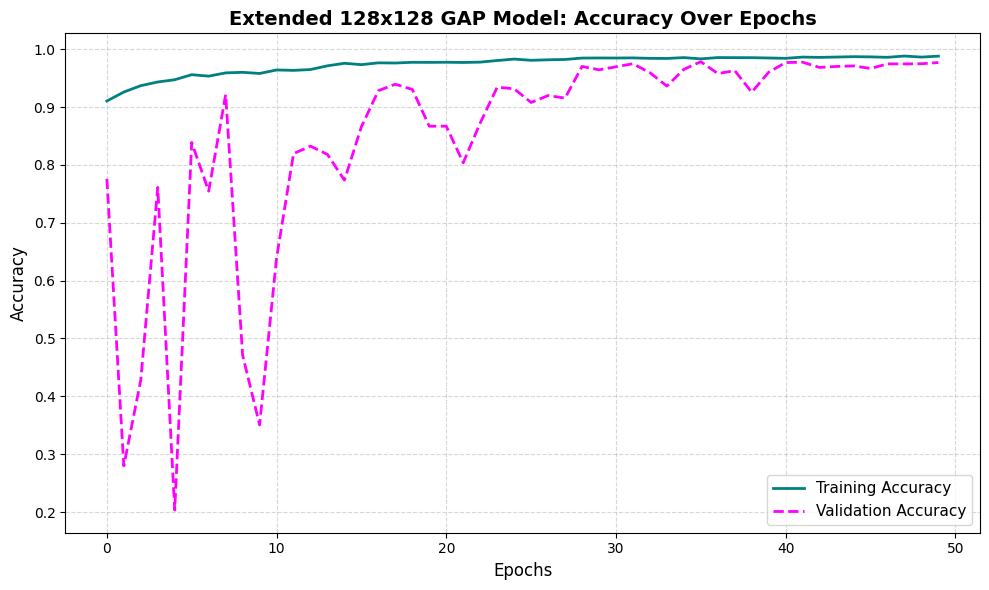

,Configuration,Overall Accuracy,Macro F1-Score,Weighted F1-Score
0,"M2 Subsampled (128x128, no-GAP)",0.9525,0.9522,0.9522
1,"M2 Full (128x128, no-GAP)",0.9699,0.9631,0.9698
2,"M2 Full (128x128, GAP) - Previous",0.2050,0.1131,0.1266
3,"M2 Full (128x128, GAP) - Extended",0.9784,0.9763,0.9783


In [38]:
import matplotlib.pyplot as plt
import pandas as pd
from sklearn.metrics import accuracy_score, classification_report

# 1. Plot Accuracy Curve for the Extended 128x128 GAP Model
if 'history_m2_128_gap_extended' in globals():
    plt.figure(figsize=(10, 6))
    plt.plot(history_m2_128_gap_extended.history['accuracy'], label='Training Accuracy', color='teal', linewidth=2)
    plt.plot(history_m2_128_gap_extended.history['val_accuracy'], label='Validation Accuracy', color='magenta', linestyle='--', linewidth=2)
    plt.title('Extended 128x128 GAP Model: Accuracy Over Epochs', fontsize=14, fontweight='bold')
    plt.xlabel('Epochs', fontsize=12)
    plt.ylabel('Accuracy', fontsize=12)
    plt.legend(fontsize=11)
    plt.grid(True, linestyle='--', alpha=0.5)
    plt.tight_layout()
    plt.show()
else:
    print('Extended GAP training history was not found.')

# 2. Comparative Analysis with Previous 128x128 Models
configs_128 = [
    ('M2 Subsampled (128x128, no-GAP)', 'y_true2', 'y_pred2'),
    ('M2 Full (128x128, no-GAP)', 'y_true_full', 'y_pred_full'),
    ('M2 Full (128x128, GAP) - Previous', 'y_true_128_gap', 'y_pred_128_gap'),
    ('M2 Full (128x128, GAP) - Extended', 'y_true_128_gap_extended', 'y_pred_128_gap_extended')
]

summary_records_128 = []

for label, true_var, pred_var in configs_128:
    if true_var in globals() and pred_var in globals():
        y_t = globals()[true_var]
        y_p = globals()[pred_var]
        acc = accuracy_score(y_t, y_p)
        report = classification_report(y_t, y_p, target_names=class_names, output_dict=True, zero_division=0)
        summary_records_128.append({
            'Configuration': label,
            'Overall Accuracy': acc,
            'Macro F1-Score': report['macro avg']['f1-score'],
            'Weighted F1-Score': report['weighted avg']['f1-score']
        })

summary_128_df = pd.DataFrame(summary_records_128)
display(summary_128_df.round(4))

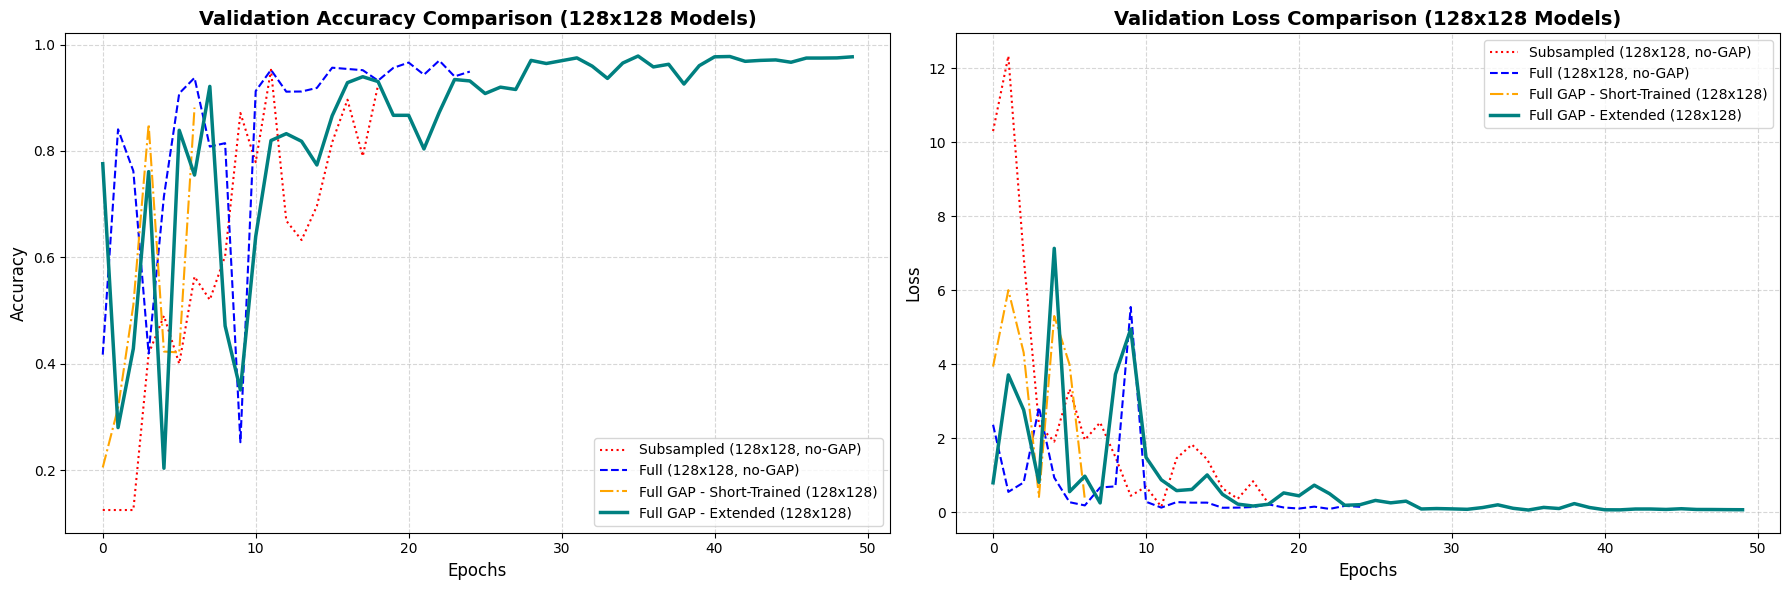

In [39]:
import matplotlib.pyplot as plt

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(18, 6))

# 1. Validation Accuracy Curves
if 'history2' in globals() and 'val_accuracy' in history2.history:
    ax1.plot(history2.history['val_accuracy'], label='Subsampled (128x128, no-GAP)', color='red', linestyle=':')
if 'history_m2_full' in globals() and 'val_accuracy' in history_m2_full.history:
    ax1.plot(history_m2_full.history['val_accuracy'], label='Full (128x128, no-GAP)', color='blue', linestyle='--')
if 'history_m2_128_gap' in globals() and 'val_accuracy' in history_m2_128_gap.history:
    ax1.plot(history_m2_128_gap.history['val_accuracy'], label='Full GAP - Short-Trained (128x128)', color='orange', linestyle='-.')
if 'history_m2_128_gap_extended' in globals() and 'val_accuracy' in history_m2_128_gap_extended.history:
    ax1.plot(history_m2_128_gap_extended.history['val_accuracy'], label='Full GAP - Extended (128x128)', color='teal', linewidth=2.5)

ax1.set_title('Validation Accuracy Comparison (128x128 Models)', fontsize=14, fontweight='bold')
ax1.set_xlabel('Epochs', fontsize=12)
ax1.set_ylabel('Accuracy', fontsize=12)
ax1.legend(fontsize=10)
ax1.grid(True, linestyle='--', alpha=0.5)

# 2. Validation Loss Curves
if 'history2' in globals() and 'val_loss' in history2.history:
    ax2.plot(history2.history['val_loss'], label='Subsampled (128x128, no-GAP)', color='red', linestyle=':')
if 'history_m2_full' in globals() and 'val_loss' in history_m2_full.history:
    ax2.plot(history_m2_full.history['val_loss'], label='Full (128x128, no-GAP)', color='blue', linestyle='--')
if 'history_m2_128_gap' in globals() and 'val_loss' in history_m2_128_gap.history:
    ax2.plot(history_m2_128_gap.history['val_loss'], label='Full GAP - Short-Trained (128x128)', color='orange', linestyle='-.')
if 'history_m2_128_gap_extended' in globals() and 'val_loss' in history_m2_128_gap_extended.history:
    ax2.plot(history_m2_128_gap_extended.history['val_loss'], label='Full GAP - Extended (128x128)', color='teal', linewidth=2.5)

ax2.set_title('Validation Loss Comparison (128x128 Models)', fontsize=14, fontweight='bold')
ax2.set_xlabel('Epochs', fontsize=12)
ax2.set_ylabel('Loss', fontsize=12)
ax2.legend(fontsize=10)
ax2.grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

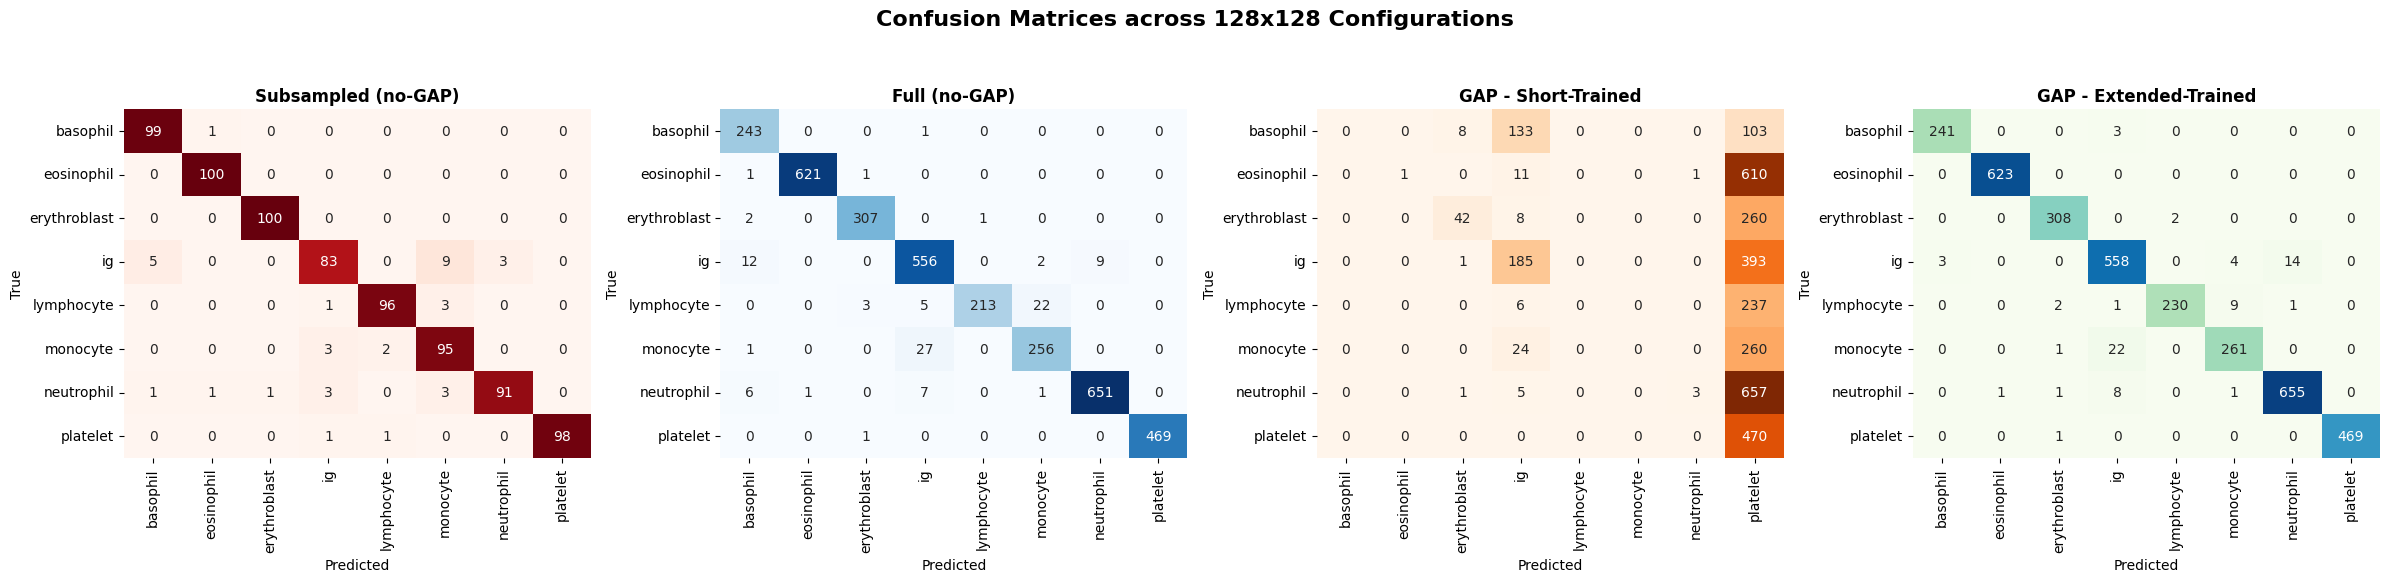

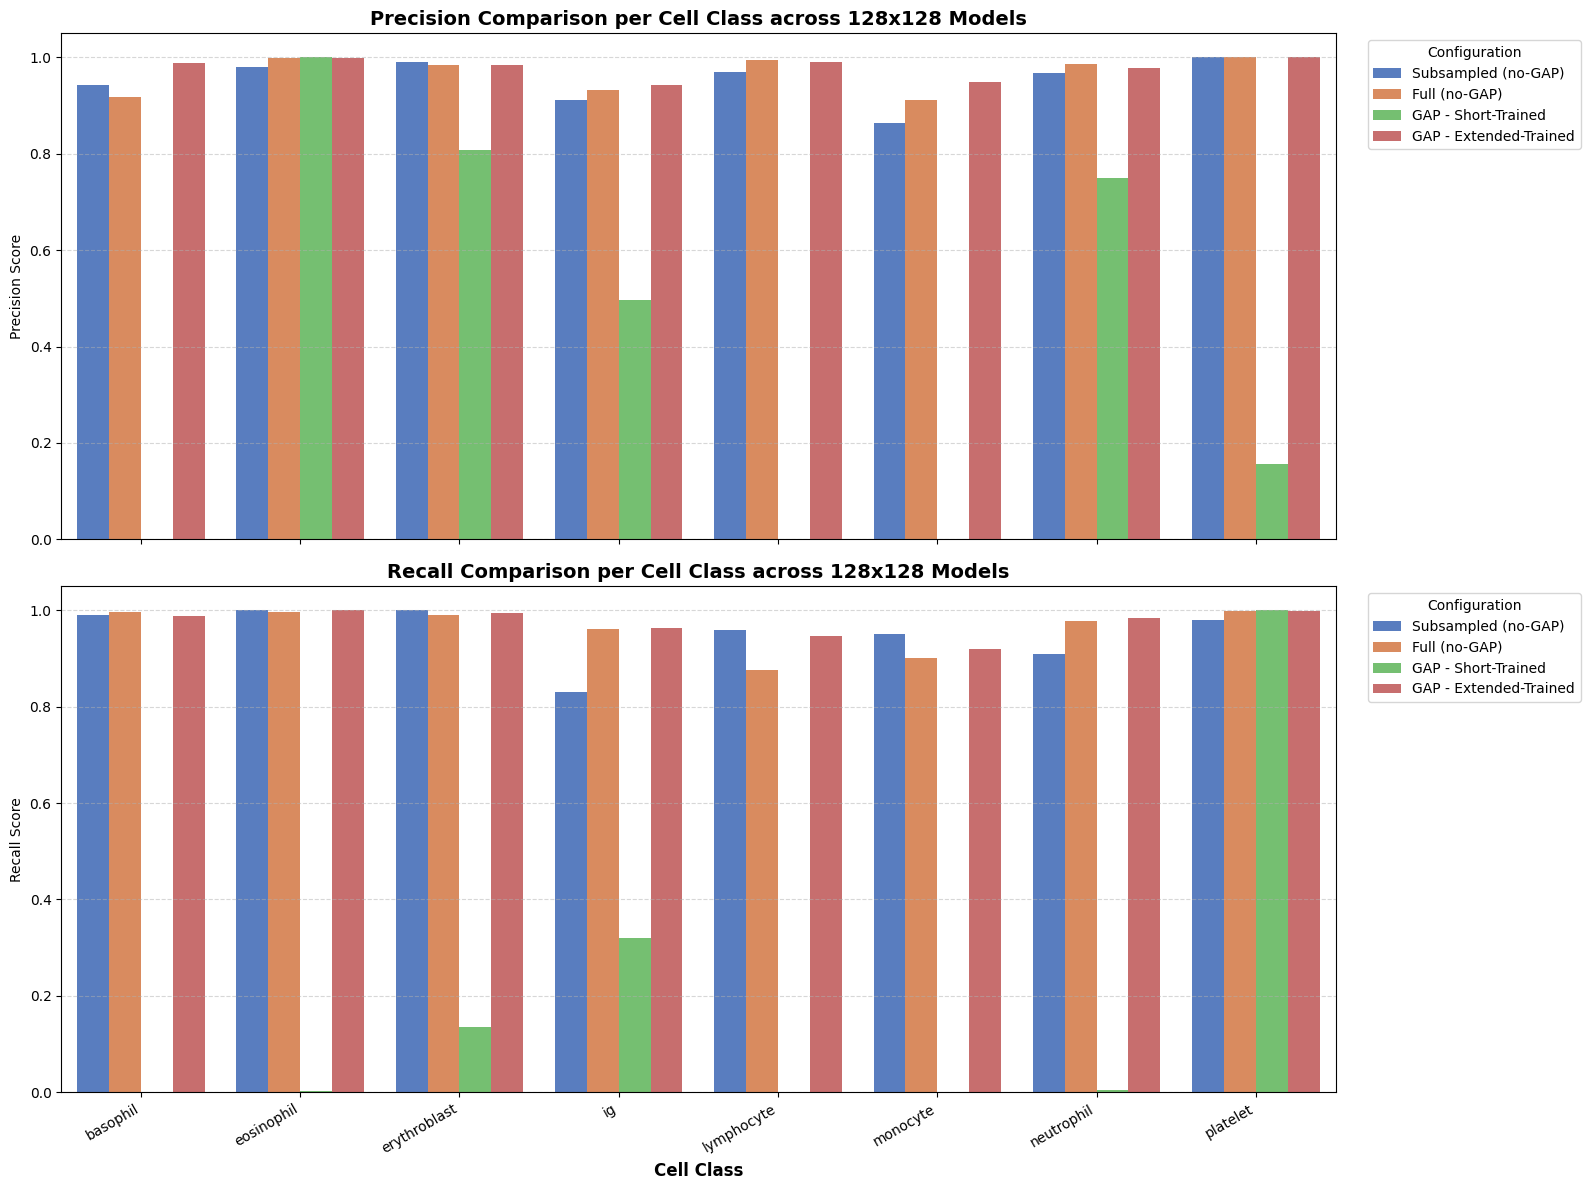

In [40]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import numpy as np
from sklearn.metrics import confusion_matrix, classification_report

# 1. Setup the 4 configurations (using valid matplotlib colormaps)
scenarios_128 = [
    ('Subsampled (no-GAP)', 'y_true2', 'y_pred2', 'Reds'),
    ('Full (no-GAP)', 'y_true_full', 'y_pred_full', 'Blues'),
    ('GAP - Short-Trained', 'y_true_128_gap', 'y_pred_128_gap', 'Oranges'),
    ('GAP - Extended-Trained', 'y_true_128_gap_extended', 'y_pred_128_gap_extended', 'GnBu')
]

# 2. Plot Confusion Matrices Side-by-Side
fig, axes = plt.subplots(1, 4, figsize=(24, 5.5))
for idx, (label, true_var, pred_var, cmap) in enumerate(scenarios_128):
    if true_var in globals() and pred_var in globals():
        y_t = globals()[true_var]
        y_p = globals()[pred_var]
        cm = confusion_matrix(y_t, y_p)

        sns.heatmap(cm, annot=True, fmt='d', cmap=cmap,
                    xticklabels=class_names, yticklabels=class_names, ax=axes[idx], cbar=False)
        axes[idx].set_title(f'{label}', fontsize=12, fontweight='bold')
        axes[idx].set_xlabel('Predicted')
        axes[idx].set_ylabel('True')
    else:
        axes[idx].text(0.5, 0.5, f'{label}\n(Data missing)', ha='center', va='center', fontsize=12)
        axes[idx].axis('off')

plt.suptitle('Confusion Matrices across 128x128 Configurations', fontsize=16, fontweight='bold', y=1.05)
plt.tight_layout()
plt.show()

# 3. Extract & Melt Precision and Recall Metrics
metric_list = []
for label, true_var, pred_var, _ in scenarios_128:
    if true_var in globals() and pred_var in globals():
        y_t = globals()[true_var]
        y_p = globals()[pred_var]
        report = classification_report(y_t, y_p, target_names=class_names, output_dict=True, zero_division=0)
        for cls in class_names:
            metric_list.append({
                'Class': cls,
                'Configuration': label,
                'Precision': report[cls]['precision'],
                'Recall': report[cls]['recall']
            })

metrics_df = pd.DataFrame(metric_list)
metrics_melted = metrics_df.melt(id_vars=['Class', 'Configuration'], value_vars=['Precision', 'Recall'],
                                  var_name='Metric', value_name='Score')

# 4. Plot Grouped Precision & Recall Graphs Per Class
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(16, 12), sharex=True)

# Precision comparison
sns.barplot(data=metrics_melted[metrics_melted['Metric'] == 'Precision'],
            x='Class', y='Score', hue='Configuration', palette='muted', ax=ax1)
ax1.set_title('Precision Comparison per Cell Class across 128x128 Models', fontsize=14, fontweight='bold')
ax1.set_ylabel('Precision Score')
ax1.set_ylim(0, 1.05)
ax1.grid(axis='y', linestyle='--', alpha=0.5)
ax1.legend(title='Configuration', bbox_to_anchor=(1.02, 1), loc='upper left')

# Recall comparison
sns.barplot(data=metrics_melted[metrics_melted['Metric'] == 'Recall'],
            x='Class', y='Score', hue='Configuration', palette='muted', ax=ax2)
ax2.set_title('Recall Comparison per Cell Class across 128x128 Models', fontsize=14, fontweight='bold')
ax2.set_xlabel('Cell Class', fontsize=12, fontweight='bold')
ax2.set_ylabel('Recall Score')
ax2.set_ylim(0, 1.05)
ax2.grid(axis='y', linestyle='--', alpha=0.5)
ax2.legend(title='Configuration', bbox_to_anchor=(1.02, 1), loc='upper left')

plt.xticks(rotation=30, ha='right')
plt.tight_layout()
plt.show()